# Coding-task bench with a baseline pilot: re-running the analysis stages on CPU

This notebook is the demo of **`method.py`** from artifact `art_0ndRfWKBWclR` (*Coding-task bench with a baseline pilot*, iteration 2). The artifact belongs to a study of **algorithm choice** in LLM code generation. Given a task with several textbook solutions, which algorithm does the model write? Does it always write the same one (the way a model asked for "a path search" might always write BFS)? What does it switch to when its default is banned in the prompt? This artifact builds the frozen *confirmation bench* for that study and measures the **baseline only**: no ban prompt is rendered anywhere.

**The bench.** There are 13 LeetCode-derived tasks, each with a catalogue of 3-6 algorithm *modes* (54 in total). For example, *k-th smallest* can be solved with a full sort, a size-k heap, heapify-and-pop, quickselect, median of medians or counting sort. For **Qwen3-8B** (official FP8 checkpoint, vLLM, T = 1.0, top_p = 1, thinking off) the artifact recorded:

- **pilot**: 50 baseline programs per task, with no mode named in the prompt;
- **forced programs**: at least 40 per mode, written when the prompt names the mode (*"Implement quickselect for this task."*). They are name-scrubbed and then scored by likelihood under the baseline prompt to estimate each mode's **forced-ratio latent probability (FRLP)**;
- **association**: 20 free-form answers per mode to *"What is the standard alternative to X for this task?"*;
- a **Llama-3.1-8B-Instruct** pilot for contrast.

Every program is labelled by a sandboxed **runtime tracer** (primary) and an **AST labeller**. A **blind LLM judge** decides when the two disagree.

**What runs here.** `method.py` is a CLI whose subcommands run as separate processes. Some stages need a GPU, a sandbox or the OpenRouter API: vLLM sampling and scoring, the subprocess tracer and the judge calls. Their **recorded outputs** are in `mini_demo_data.json`, which holds the per-sample rows with all labels, the likelihood scores and the cached judge answers. **Every CPU stage is re-run below with the original code**, and every re-derived number is compared with the value the original run published.

| `method.py` step | what it does | in this notebook |
|---|---|---|
| `specs` | freeze the task wording and catalogue; sha256 commitment | **re-run**; hash checked against `commitments.log` |
| `gen --job A/C/D` | vLLM sampling: pilot, association, forced, Llama pilot (GPU) | recorded samples; prompts re-rendered and audited |
| `label` | hidden tests, AST labeller, runtime tracer, judge on disagreement | **AST labeller and combination rule re-run**; runtime labels and judge answers recorded |
| `gate` | gold set, kappa(runtime, AST), adjudication by 2 judges plus a tie-break | **metrics re-run** on the stored gold sets |
| `order --stage A` | association map, ladder / association / proximity nominations, task order | **re-run**; order hash checked |
| `score` | vLLM prompt-logprob of each forced program under each prompt (GPU) | recorded scores |
| `frlp` | FRLP cells, validity, coverage | **re-run** |
| `order --stage B` | FRLP-broken ladder plus forced-program proximity; Kendall τ against Stage A | **re-run**; order hash checked |
| `freeze` | first 12 gated tasks in Stage-A order; per-task file hashes; hash chain | **re-run** for the files carried in the data |
| `report` | pilot statistics (Wilson CIs, Hill numbers), forced adherence | **re-run** for Qwen and Llama |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (method.py's logger) and rapidfuzz (token Levenshtein distance in canon.py) — NOT on Colab, always install
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, matplotlib — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py's import block (as-is) ----
import argparse
import json
import sys
from pathlib import Path

from loguru import logger

# ---- imports of the bench/common modules used below (commit, prompts, astrules, stats, report, gate, canon, order,
# ---- frlp, finalize); their own module-level imports are collected here
import ast
import builtins
import hashlib
import io
import itertools
import keyword
import math
import random
import re
import statistics
import time
import tokenize
from collections import Counter, defaultdict

import numpy as np
from rapidfuzz.distance import Levenshtein

# ---- notebook addition: plots
import matplotlib.pyplot as plt

# method.py's logger set-up (stdout sink only: this demo writes no log files)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}");  # ';' hides the handler id

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-2/experiment-11/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EX = {e["task"]: e for e in data["datasets"][0]["examples"]}  # one example per bench task
print(data["metadata"]["description"])
print(f"{len(EX)} tasks: {list(EX)}")
print("model:", data["metadata"]["model"])
for t, e in list(EX.items())[:1]:
    print(f"\nexample {t}: " + ", ".join(f"{k}: {len(v)}" for k, v in e.items() if isinstance(v, (list, dict))))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Demo subset of the coding-task bench with a baseline pilot (iteration 2): one example per bench task with the per-sample rows, likelihood scores and frozen files that the CPU-only stages of method.py read, plus the values the original run reported.
13 tasks: ['T03', 'T05', 'T06', 'T14', 'T10', 'T08', 'T04', 'T11', 'T13', 'R1', 'R2', 'R3', 'R6']
model: Qwen/Qwen3-8B-FP8 (vLLM 0.11.0, FP8 Marlin, eager); decoding T=1.0 top_p=1.0 top_k=-1 min_p=0, thinking off

example T03: spec: 14, references: 6, pilot: 50, forced: 280, llama_pilot: 50, association: 120, gold_set: 28, program_scores: 180, commitment: 2, reported: 11


## Configuration

Every tunable parameter of the CPU stages is set here; the original run's value is in brackets.

- **At the original values** every re-derived number must equal the published one, and each comparison line prints `match`. Hashes are compared exactly; floats are compared to a relative 1e-9, because their last digit can change between numpy builds.
- **Smaller values** (fewer tasks, smaller FRLP sets, fewer resamples) run faster but change the numbers, so the comparison lines then print `DIFF`. That is expected.

With all 13 tasks at the original values, the stages after the install take well under a minute on a CPU.

In [5]:
# ---- Config: tunable parameters of the CPU stages [original value] ----
N_TASKS = 13            # bench tasks processed, in the catalogue's hypothesis order [13 = all]
FRLP_M = 30             # programs per frozen FRLP set M_j (gate.py FRLP_M) [30]; the data carries scores for <= 30
PROX_MAX = 30           # programs per side in the proximity medians (order.proximity) [30]
KAPPA_BOOT_REPS = 1000  # bootstrap resamples of the gate's kappa CI (stats.kappa_bootstrap) [1000]
RAREFY_DEPTH = 25       # rarefaction depth for Hill-1 of correct pilot programs (report.pilot_stats) [25]
RAREFY_REPS = 1000      # rarefaction draws (stats.rarefied_hill1) [1000]
HILL_BOOT_REPS = 300    # bootstrap resamples of the rarefied-Hill CI [300]
HILL_BOOT_INNER = 200   # rarefaction draws inside each bootstrap resample [200]
MAX_FROZEN = 12         # freeze cap of the stop rule (method.py freeze --max-tasks) [12]

ORIGINAL = dict(N_TASKS=13, FRLP_M=30, PROX_MAX=30, KAPPA_BOOT_REPS=1000, RAREFY_DEPTH=25, RAREFY_REPS=1000,
                HILL_BOOT_REPS=300, HILL_BOOT_INNER=200, MAX_FROZEN=12)
AT_ORIGINAL = all(globals()[k] == v for k, v in ORIGINAL.items())
print("running at the original settings:", AT_ORIGINAL)

running at the original settings: True


## 1. `specs`: the frozen catalogue and the commitment chain

`bench/common/catalogue.py` holds one card per task:
- the description: new wording, with no complexity hints and no LeetCode follow-ups;
- the catalogue of algorithm modes, each with a display name and a one-line mechanism;
- an alias lexicon, used for name scrubbing and for mapping association answers.

The original module writes the 13 cards out as a Python literal. Here they are rebuilt from the frozen `bench/<task_id>/spec.json` copies carried in the data. That makes the rebuild a strict test: if it differed by a single character, the `spec_v1` hash recomputed below would not match the one committed in `commitments.log`.

`bench/common/commit.py` keeps a sha256 hash chain: each line stores the hash of its payload and of the previous line. The notebook keeps its own chain in memory (`COMMITMENTS`) and compares the payload hashes with the published log.

In [6]:
# ---- bench/common/catalogue.py: the frozen catalogue cards (rebuilt from the frozen spec.json files) ----
_SPEC0 = EX["T03"]["spec"]
FORMAT_LINE = _SPEC0["format_line"]
# exp1's five forced paraphrases are ids 0-4; ids 5-9 are new (frozen, see deviations).
FORCED_TEMPLATES = _SPEC0["forced_templates"]
DESCRIPTIVE_FORCED_TEMPLATE = _SPEC0["descriptive_forced_template"]
ASSOCIATION_TEMPLATE = _SPEC0["association_template"]

# Hypothesis task order (tie-break of the disagreement ranking); the demo keeps its first N_TASKS tasks.
FULL_TASK_ORDER = data["metadata"]["task_order_hypothesis"]
TASK_ORDER = FULL_TASK_ORDER[:N_TASKS]

TASKS: dict[str, dict] = {
    e["task"]: {"task_id": e["spec"]["task_id"], "leetcode_ids": e["spec"]["leetcode_ids"],
                "signature": e["spec"]["signature"], "description": e["spec"]["description"],
                "bounds": e["spec"]["bounds"],
                "modes": {c["mode"]: (c["display_name"], c["mechanism"]) for c in e["spec"]["catalogue"]},
                "aliases": e["spec"]["aliases"]}
    for e in data["datasets"][0]["examples"]}


def display_name(task: str, mode: str) -> str:
    return TASKS[task]["modes"][mode][0]


def mode_description(task: str, mode: str) -> str:
    return TASKS[task]["modes"][mode][1]


# ---- bench/common/commit.py: sha256 hash-chain commitments ----
# each line of commitments.log is {ts, kind, sha256, prev_line_sha256, ...}
def canon_json(obj) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def commit(log_lines: list[str], kind: str, payload_sha256: str, extra: dict | None = None) -> dict:
    lines = log_lines  # original: the lines of commitments.log
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    rec = {"ts": time.strftime("%Y-%m-%dT%H:%M:%S%z"), "kind": kind, "sha256": payload_sha256,
           "prev_line_sha256": prev}
    if extra:
        rec.update(extra)
    log_lines.append(canon_json(rec))  # original: appended to commitments.log
    return rec


def verify_chain(lines: list[str]) -> bool:  # original: reads the lines of commitments.log
    prev = "0" * 64
    for line in lines:
        rec = json.loads(line)
        if rec["prev_line_sha256"] != prev:
            return False
        prev = sha256_text(line)
    return True


COMMITMENTS: list[str] = []                           # this notebook's own chain (in memory)
PUBLISHED_LOG = data["metadata"]["commitments_log"]   # the artifact's commitments.log
COMMITTED = {json.loads(l)["kind"]: json.loads(l) for l in PUBLISHED_LOG}

# ---- notebook addition: bookkeeping of the comparisons with the published values ----
CHECKS: list[tuple[str, str, bool, str]] = []


def check(stage: str, what: str, ok: bool, detail: str = "") -> None:
    CHECKS.append((stage, what, bool(ok), detail))
    print(f"[{'match' if ok else 'DIFF '}] {stage}: {what}" + (f"  ({detail})" if detail else ""))


def same(a, b, rel: float = 1e-9) -> bool:
    """Equality of JSON-like values; floats up to a relative 1e-9, because the last digit of a float can differ
    between numpy builds and CPUs (summation order, SIMD exp/log)."""
    a, b = json.loads(json.dumps(a, default=str)), b
    return _same(a, b, rel)


def _same(a, b, rel):
    if isinstance(a, bool) or isinstance(b, bool) or a is None or b is None:
        return a == b
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        return math.isclose(a, b, rel_tol=rel, abs_tol=1e-12) or (math.isnan(a) and math.isnan(b))
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(_same(a[k], b[k], rel) for k in a)
    if isinstance(a, list) and isinstance(b, list):
        return len(a) == len(b) and all(_same(x, y, rel) for x, y in zip(a, b))
    return a == b


for t in TASK_ORDER:
    c = TASKS[t]
    print(f"{t:4s} {c['task_id']:36s} K={len(c['modes'])}  modes: {', '.join(c['modes'])}")

T03  T03_kth_smallest                     K=6  modes: full_sort, size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort
T05  T05_two_sum                          K=4  modes: hash_map, sort_two_pointers, brute_force, sort_binary_search
T06  T06_find_duplicate                   K=5  modes: hash_set, sort_adjacent, floyd, value_binary_search, index_marking
T14  T14_top_k_frequent                   K=4  modes: sort_by_count, heap, bucket_sort, quickselect_counts
T10  T10_connected_components             K=4  modes: bfs, dfs, union_find, label_propagation
T08  T08_fibonacci                        K=4  modes: iteration, memo_recursion, matrix_power, fast_doubling
T04  T04_substring_search                 K=6  modes: naive, kmp, rabin_karp, z_algorithm, bmh, builtin
T11  T11_longest_increasing_subsequence   K=3  modes: quadratic_dp, patience_bisect, fenwick
T13  T13_merge_intervals                  K=3  modes: sort_sweep, interval_tree, union_find
R1   R1_non_overlapping_inte

These are the only three prompt builders of the bench (`bench/common/prompts.py`, verbatim):

- **Scaffold** (from exp1): `[condition segment] + blank line + DESCRIPTION + blank line + FORMAT`.
- **Forced prompts** prepend one of exp1's paraphrases, ids 0-4 (*"Implement {j} for this task."*, …), or the descriptive variant, id −1 (*"Implement the approach described as: \<mechanism\>"*).
- No ban, mention or novelty builder exists, on purpose.

`render_chat` (the Qwen3 chat template with thinking disabled) needs the tokenizer and is used only by the GPU jobs, so it is left out.

In [7]:
# ---- bench/common/prompts.py ----
# The only three prompt builders of the bench: baseline, forced and association.
#
# Scaffold (exp1): [condition segment] + blank line + SPEC, SPEC = DESCRIPTION + blank line + FORMAT,
# first character of every segment upper-cased.  No ban / mention / neutral / nonce / novelty
# builder exists on purpose.


def _cap(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def spec_text(task: str) -> str:
    return _cap(TASKS[task]["description"]) + "\n\n" + _cap(FORMAT_LINE)


def build_baseline(task: str) -> str:
    return spec_text(task)


def forced_segment(task: str, mode: str, k: int) -> str:
    if k == -1:  # descriptive variant (job C only, logged)
        d = mode_description(task, mode)
        d = d[0].upper() + d[1:]
        return _cap(DESCRIPTIVE_FORCED_TEMPLATE.format(d=d.rstrip(".") + "."))
    return _cap(FORCED_TEMPLATES[k].format(j=display_name(task, mode)))


def build_forced(task: str, mode: str, k: int) -> str:
    return forced_segment(task, mode, k) + "\n\n" + spec_text(task)


def build_association(task: str, mode: str) -> str:
    return _cap(TASKS[task]["description"]) + "\n\n" + _cap(ASSOCIATION_TEMPLATE.format(x=display_name(task, mode)))

`method.py specs` (`cmd_specs`, file writes kept in memory) builds every task's frozen spec and commits the sha256 of all of them. The cell then runs three checks:
- the recomputed `spec_v1` hash against the first line of `commitments.log`;
- each `spec.json` text against its per-file hash in `bench/commitment.json`;
- a print of one rendered prompt of each kind.

In [8]:
SPEC_FILES: dict[str, str] = {}  # bench/<task_id>/spec.json text, as `specs` writes it


def cmd_specs(args: argparse.Namespace) -> None:
    # (the bench.common imports are the cells above)
    frozen = {}
    for t in TASK_ORDER:
        c = TASKS[t]
        spec = {"task": t, "task_id": c["task_id"], "leetcode_ids": c["leetcode_ids"], "signature": c["signature"],
                "description": c["description"], "format_line": FORMAT_LINE, "spec_text": spec_text(t),
                "bounds": c["bounds"],
                "catalogue": [{"mode": m, "display_name": v[0], "mechanism": v[1]} for m, v in c["modes"].items()],
                "aliases": c["aliases"], "forced_templates": FORCED_TEMPLATES,
                "descriptive_forced_template": DESCRIPTIVE_FORCED_TEMPLATE,
                "association_template": ASSOCIATION_TEMPLATE, "spec_version": 1}
        SPEC_FILES[t] = json.dumps(spec, indent=1)  # original: written to bench/<task_id>/spec.json
        frozen[t] = spec
    h = sha256_text(canon_json(frozen))
    rec = commit(COMMITMENTS, "spec_v1", h, {"n_tasks": len(frozen)})
    logger.info(f"spec v1 frozen for {len(frozen)} tasks: {rec}")


cmd_specs(argparse.Namespace())

ours = json.loads(COMMITMENTS[-1])["sha256"]
check("specs", "spec_v1 hash = commitments.log", ours == COMMITTED["spec_v1"]["sha256"],
      f"{ours[:16]}…" + ("" if len(TASK_ORDER) == 13 else ", only equal with all 13 tasks"))
frozen_specs = [t for t in TASK_ORDER if EX[t]["commitment"]]
check("specs", f"spec.json hashes = bench/commitment.json ({len(frozen_specs)} frozen tasks)",
      all(sha256_text(SPEC_FILES[t]) == EX[t]["commitment"]["files"]["spec.json"] for t in frozen_specs))

t0 = TASK_ORDER[0]
m0 = list(TASKS[t0]["modes"])[-1]
print("\n--- baseline prompt (", t0, ") ---\n" + build_baseline(t0))
print("\n--- forced prompt, paraphrase 0, mode", m0, "---\n" + forced_segment(t0, m0, 0))
print("--- forced prompt, descriptive variant (k = -1) ---\n" + forced_segment(t0, m0, -1))
print("\n--- association prompt, X =", list(TASKS[t0]["modes"])[0], "---\n" + build_association(t0, list(TASKS[t0]["modes"])[0]))

06:18:23|INFO   |spec v1 frozen for 13 tasks: {'ts': '2026-10-24T06:18:23+0000', 'kind': 'spec_v1', 'sha256': '87a6a7a34ce1cf7e25eafe35b36309fa92076c1fee28fced2e19fa9c4ae56223', 'prev_line_sha256': '0000000000000000000000000000000000000000000000000000000000000000', 'n_tasks': 13}


[match] specs: spec_v1 hash = commitments.log  (87a6a7a34ce1cf7e…)
[match] specs: spec.json hashes = bench/commitment.json (12 frozen tasks)

--- baseline prompt ( T03 ) ---
Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

--- forced prompt, paraphrase 0, mode counting_sort ---
Implement counting sort for this task.
--- forced prompt, descriptive variant (k = -1) ---
Implement the approach described as: Count occurrence

## 2. `gen --job A/C/D`: the recorded samples (GPU, not re-run)

On the original machine, `gen_vllm.py` sampled Qwen3-8B-FP8 with vLLM 0.11 (FP8 Marlin, eager mode). Decoding was T = 1.0, top_p = 1, top_k = −1 and min_p = 0, with at most 1,024 tokens and thinking disabled. Three jobs ran:

- **Job A**: 50 pilot samples per task, 20 association answers per mode, and 5 paraphrases × 8 rounds = 40 forced attempts per mode.
- **Job C**: forced top-ups. Modes with fewer than 30 usable programs got 4 more rounds. Modes with adherence below 0.3 got 20 attempts with the descriptive variant.
- **Job D**: the Llama-3.1-8B-Instruct pilot.

**Seeds** start from base 20261020 and add an offset:

| condition | offset |
|---|---|
| pilot | `1000·task_idx + s` |
| association | `10^5 + 100·mode_idx + s` |
| forced | `10^6 + 1000·mode_idx + 10·round + k` (the descriptive variant uses slot k = 9) |

vLLM is not bit-reproducible across batch compositions, so the demo uses the recorded samples. The code of a sample is the first fenced python block of the answer.

This cell does three things:
- rebuilds the in-memory versions of `data/samples_*.jsonl`;
- checks the seed formulas;
- repeats the **no-ban audit** of `report.py`: every prompt is re-rendered with the builders above and searched for a superset ban/novelty lexicon. The original audit found 0 hits in 4,310 prompts.

In [9]:
# in-memory versions of data/samples_pilot.jsonl, data/samples_forced.jsonl (+ top-ups), data/samples_llama_pilot.jsonl
# and data/association_raw.jsonl: the recorded outputs of GPU jobs A, C and D (file order kept)
PILOT = [r for t in TASK_ORDER for r in EX[t]["pilot"]]
FORCED = [r for t in TASK_ORDER for r in EX[t]["forced"]]
LLAMA = [r for t in TASK_ORDER for r in EX[t]["llama_pilot"]]
ASSOC_RAW = [{"task": a["task"], "mode": a["X"], "sample_id": a["sample_id"], "seed": a["seed"], "text": a["answer"]}
             for t in TASK_ORDER for a in EX[t]["association"]]
print(f"pilot {len(PILOT)} | forced {len(FORCED)} | Llama pilot {len(LLAMA)} | association answers {len(ASSOC_RAW)}")

# seed formulas of gen_vllm.py (global task / mode indices over the full catalogue)
BASE = data["metadata"]["decoding"]["seed_base"]
MODE_IDX = {tm: i for i, tm in enumerate((t, m) for t in FULL_TASK_ORDER for m in TASKS[t]["modes"])}
seed_pilot = all(r["seed"] == BASE + 1000 * FULL_TASK_ORDER.index(r["task"]) + int(r["sample_id"].rsplit(":", 1)[1])
                 for r in PILOT)
seed_assoc = all(a["seed"] == BASE + 10**5 + 100 * MODE_IDX[(a["task"], a["mode"])] + int(a["sample_id"].rsplit(":", 1)[1])
                 for a in ASSOC_RAW)
seed_forced = all(r["seed"] == BASE + 10**6 + 1000 * MODE_IDX[(r["task"], r["forced_mode"])] + 10 * r["round"]
                  + (9 if r["paraphrase_id"] == -1 else r["paraphrase_id"]) for r in FORCED)
check("gen", "seeds follow the pilot / association / forced formulas", seed_pilot and seed_assoc and seed_forced)

# ---- report.py: the no-ban audit, on prompts re-rendered with the three builders ----
BAN_RE = re.compile(r"(?i)\b(do not|don't|must not|never|without using|avoid|instead of|not allowed|forbidden|banned?|"
                    r"prohibit\w*|zorblax|novel|unusual|creative|unconventional)\b")

rendered = ([build_baseline(r["task"]) for r in PILOT]
            + [build_forced(r["task"], r["forced_mode"], r["paraphrase_id"]) for r in FORCED]
            + [build_association(a["task"], a["mode"]) for a in ASSOC_RAW])
hits = [p for p in rendered if BAN_RE.search(p)]
rep = data["metadata"]["reported"]["no_ban_audit"]
check("gen", f"no-ban audit: {len(rendered)} prompts, {len(hits)} lexicon hits",
      len(hits) == rep["ban_lexicon_hits"] and (len(rendered) == rep["n_prompts_audited"] or len(TASK_ORDER) < 13),
      f"reported {rep['ban_lexicon_hits']} hits in {rep['n_prompts_audited']} prompts")

r = next(r for r in FORCED if r["paraphrase_id"] == 0)
print(f"\nexample forced program {r['sample_id']} (asked for {r['forced_mode']}, labelled {r['label']}, passed={r['passed']}):")
print(r["code"])

pilot 650 | forced 2580 | Llama pilot 650 | association answers 1080
[match] gen: seeds follow the pilot / association / forced formulas
[match] gen: no-ban audit: 4310 prompts, 0 lexicon hits  (reported 0 hits in 4310 prompts)

example forced program T03:forced:counting_sort:r0:k0 (asked for counting_sort, labelled counting_sort, passed=True):
def solve(nums, k):
    # Find the minimum and maximum values in nums
    min_val = min(nums)
    max_val = max(nums)
    
    # Initialize a count array to store the frequency of each value
    count = [0] * (max_val - min_val + 1)
    
    # Count the occurrences of each value
    for num in nums:
        count[num - min_val] += 1
    
    # Find the k-th smallest value by accumulating counts
    for i in range(len(count)):
        if k <= count[i]:
            return min_val + i
        else:
            k -= count[i]



## 3. `label`: which algorithm is this program?

Every attempt is labelled three ways:

1. **Runtime labeller** (primary): `tracer.py` + `probes.py` + `rtrules.py`. The program runs in a sandboxed `python3.12 -I -S` subprocess on instrumented probe inputs, while the tracer counts comparisons, heap and bisect calls, deque pops, recursion and list access order. It needs subprocess sandboxing and is **not re-run here**; its labels are in the data.
2. **AST labeller**: `astrules.py`, below, verbatim. Static per-task rules over imports, call names, loop depth, recursion and characteristic expressions; identifier hints count only as weak evidence.
3. **Blind judge**: gemini-2.5-flash-lite on name-scrubbed code. It is asked only when the runtime label is `unknown` or disagrees with a known AST label. Its answers are cached in the data.

`ast_label(task, code)` returns a catalogue mode, `other`, `unknown` or `invalid`.

In [10]:
# ---- bench/common/astrules.py (verbatim) ----
# Static (AST) labeller: imports, call names, loop/recursion structure, characteristic expressions;
# identifier hints are weak evidence only.  ast_label(task, code) -> mode | 'other' | 'unknown' | 'invalid'.


class F:
    """AST feature bag of one program."""

    def __init__(self, code: str):
        self.code = code
        self.tree = ast.parse(code)
        self.calls = Counter()
        self.attr_calls = Counter()
        self.imports = set()
        self.names = Counter()
        self.funcs = {}
        self.recursive = set()
        self.max_loop_depth = 0
        self.n_loops = 0
        self.classes = 0
        self.decorators = Counter()
        self.bitand_neg = False
        self.pop0 = 0
        self.pop_noarg = 0
        self.popleft = 0
        self.subscript_nested = 0
        self.consts = Counter()
        for node in ast.walk(self.tree):
            if isinstance(node, ast.Import):
                for a in node.names:
                    self.imports.add(a.name.split(".")[0])
            elif isinstance(node, ast.ImportFrom):
                if node.module:
                    self.imports.add(node.module.split(".")[0])
                for a in node.names:
                    self.imports.add(a.name)
            elif isinstance(node, ast.Call):
                fn = node.func
                if isinstance(fn, ast.Name):
                    self.calls[fn.id] += 1
                elif isinstance(fn, ast.Attribute):
                    self.attr_calls[fn.attr] += 1
                    if isinstance(fn.value, ast.Name):
                        self.calls[f"{fn.value.id}.{fn.attr}"] += 1
                    if fn.attr == "pop":
                        if not node.args:
                            self.pop_noarg += 1
                        elif isinstance(node.args[0], ast.Constant) and node.args[0].value == 0:
                            self.pop0 += 1
                    if fn.attr == "popleft":
                        self.popleft += 1
            elif isinstance(node, ast.Name):
                self.names[node.id] += 1
            elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                self.funcs[node.name] = node
                for d in node.decorator_list:
                    dn = d.func if isinstance(d, ast.Call) else d
                    nm = dn.attr if isinstance(dn, ast.Attribute) else (dn.id if isinstance(dn, ast.Name) else "?")
                    self.decorators[nm] += 1
                for sub in ast.walk(node):
                    if isinstance(sub, ast.Call) and isinstance(sub.func, ast.Name) and sub.func.id == node.name:
                        self.recursive.add(node.name)
                    if isinstance(sub, ast.Call) and isinstance(sub.func, ast.Attribute) and sub.func.attr == node.name:
                        self.recursive.add(node.name)
            elif isinstance(node, ast.ClassDef):
                self.classes += 1
            elif isinstance(node, ast.BinOp) and isinstance(node.op, ast.BitAnd):
                for side in (node.left, node.right):
                    if isinstance(side, ast.UnaryOp) and isinstance(side.op, ast.USub):
                        self.bitand_neg = True
            elif isinstance(node, ast.Subscript) and isinstance(node.slice, ast.Subscript):
                self.subscript_nested += 1
            elif isinstance(node, ast.Constant) and isinstance(node.value, (int, str)):
                self.consts[node.value] += 1
        self._loop_depth(self.tree, 0)
        self.low = code.lower()
        self.idents = {n.lower() for n in self.names} | {f.lower() for f in self.funcs}

    def _loop_depth(self, node, d):
        for ch in ast.iter_child_nodes(node):
            if isinstance(ch, (ast.For, ast.While)):
                self.n_loops += 1
                self.max_loop_depth = max(self.max_loop_depth, d + 1)
                self._loop_depth(ch, d + 1)
            elif isinstance(ch, (ast.FunctionDef, ast.Lambda, ast.AsyncFunctionDef, ast.ClassDef)):
                self._loop_depth(ch, 0)
            else:
                self._loop_depth(ch, d)

    def has(self, *names):
        return any(self.calls.get(n) or self.attr_calls.get(n) for n in names)

    def ident(self, *subs):
        return any(any(s in i for s in subs) for i in self.idents)

    def rx(self, pattern):
        return re.search(pattern, self.code) is not None

    @property
    def memo(self):
        return bool(self.decorators.get("lru_cache") or self.decorators.get("cache") or self.ident("memo", "cache"))


def _bisect(f):
    return f.has("bisect_left", "bisect_right", "bisect", "insort", "insort_left", "insort_right")


def _manual_bsearch(f):
    return f.ident("mid") and f.rx(r"while\s+\w+\s*(<|<=)\s*\w+")


def _uf(f):
    return (f.ident("parent", "root") and (f.ident("find") or "find" in f.funcs)) or f.ident("union", "dsu", "disjoint")


def _heapish(f):
    return f.has("heappush", "heappop", "heapify", "heappushpop", "heapreplace", "nlargest", "nsmallest") or \
        f.has("PriorityQueue")


def t03(f):
    if f.has("nsmallest", "nlargest"):
        return "size_k_heap"
    if f.has("heapify") and f.has("heappop") and not (f.has("heappush") and f.rx(r"len\(\s*\w+\s*\)\s*>")):
        return "heapify_pop"
    if f.has("heappush", "heappushpop", "heapreplace"):
        if f.rx(r"len\(\s*\w+\s*\)\s*(>|>=|==|<|<=)\s*k") or f.has("heappushpop", "heapreplace"):
            return "size_k_heap"
        if f.has("heappop"):
            return "heapify_pop"
    if f.rx(r"\b5\b") and (f.ident("median", "group", "chunk") or f.rx(r":\s*\w+\s*\+\s*5\]")) and f.recursive | {"x"}:
        if f.ident("median") or f.rx(r"range\([^)]*,\s*5\)"):
            return "median_of_medians"
    if f.rx(r"\[0\]\s*\*\s*\(?\s*(max|hi|high|max_val|maxv|mx|\w+_max|20001|20000|10001)") or \
            (f.ident("count") and f.rx(r"\[0\]\s*\*\s*\(") and f.has("min", "max")) or \
            f.rx(r"for\s+\w+\s+in\s+range\(\s*(min|lo|low|min_val|mn|-\s*10000|offset)\w*") and f.ident("count", "freq"):
        return "counting_sort"
    if (f.has("Counter") or f.ident("count", "freq")) and f.rx(r"sorted\(\s*\w+\.?(keys|items)?\(?\)?\s*\)"):
        return "unknown"
    if f.ident("pivot", "partition", "quickselect", "select") and not f.has("sort", "sorted"):
        return "quickselect"
    if f.ident("pivot") and f.recursive:
        return "quickselect"
    if f.has("sorted", "sort") and not f.ident("pivot"):
        return "full_sort"
    if f.ident("pivot"):
        return "quickselect"
    return "unknown"


def t04(f):
    if f.has("find", "index") and f.rx(r"\.(find|index)\(\s*needle") or f.rx(r"needle\s+in\s+haystack"):
        if not f.rx(r"for\s+\w+\s+in\s+range"):
            return "builtin"
    if f.rx(r"needle\s*\+\s*['\"]") or f.rx(r"['\"][$#|@]['\"]\s*\+") or f.ident("z_arr", "zarr", "z_func", "zfunc") or \
            (f.ident("z") and f.rx(r"\bz\s*=\s*\[0\]")):
        return "z_algorithm"
    if f.ident("lps", "fail", "prefix_func", "pi", "kmp", "next_arr", "partial") and f.rx(r"\w+\[\s*\w+\s*-\s*1\s*\]"):
        return "kmp"
    if f.has("ord") and (f.has("pow") or f.rx(r"%\s*\w*(mod|prime|q|MOD)\w*") or f.rx(r"\*\*")) or f.ident("rolling", "hash"):
        return "rabin_karp"
    if f.ident("shift", "bad_char", "badchar", "bad_character", "skip", "last_occ", "last", "table", "horspool", "occ") and \
            (f.rx(r"-=\s*1") or f.rx(r"range\([^)]*-\s*1\s*,\s*-1\s*,\s*-1\)")):
        return "bmh"
    if f.has("startswith") or f.rx(r"haystack\[\s*\w+\s*:\s*\w+\s*\+\s*\w+\s*\]\s*==") or \
            f.rx(r"==\s*needle") or f.max_loop_depth >= 2:
        return "naive"
    if f.has("find", "index") or f.rx(r"\bin\s+haystack"):
        return "builtin"
    return "unknown"


def t05(f):
    if f.max_loop_depth >= 2 and not f.has("sorted", "sort") and not f.rx(r"in\s+\w*(seen|map|dict|lookup|index|pos|hash)\w*"):
        if f.rx(r"\[\s*i\s*\]\s*\+\s*\w+\[\s*j\s*\]") or f.rx(r"range\(\s*i\s*\+\s*1"):
            return "brute_force"
    if f.has("sorted", "sort"):
        if _bisect(f) or _manual_bsearch(f) and not f.ident("left", "right") or f.ident("mid"):
            if not (f.ident("left") and f.ident("right") and f.rx(r"while\s+left\s*<\s*right") and not f.ident("mid")):
                return "sort_binary_search"
        if f.rx(r"while\s+\w+\s*<\s*\w+") and (f.rx(r"-=\s*1") or f.rx(r"\+=\s*1")):
            return "sort_two_pointers"
    if f.rx(r"\bin\s+\w+") and (f.rx(r"\{\s*\}") or f.has("dict", "defaultdict")):
        return "hash_map"
    if f.max_loop_depth >= 2:
        return "brute_force"
    return "unknown"


def t06(f):
    if f.ident("slow", "tortoise") and f.ident("fast", "hare"):
        return "floyd"
    if f.rx(r"nums\[\s*nums\[") and f.n_loops >= 2 and not f.rx(r"=\s*-"):
        return "floyd"
    if f.ident("mid") and f.rx(r"<=\s*mid|mid\s*>=") and (f.ident("count", "cnt") or f.has("sum")):
        return "value_binary_search"
    if f.rx(r"nums\[\s*\w+\s*\]\s*\*=\s*-1") or f.rx(r"=\s*-\s*nums\[") or f.rx(r"nums\[[^\]]*abs") or \
            (f.has("abs") and f.rx(r"<\s*0")):
        return "index_marking"
    if f.rx(r"nums\[\s*nums\[\s*\w+\s*\]\s*\]\s*,\s*nums\[") or f.rx(r"nums\[\s*\w+\s*\]\s*,\s*nums\[\s*nums"):
        return "index_marking"
    if f.has("sorted", "sort") and f.rx(r"\[\s*\w+\s*\]\s*==\s*\w+\[\s*\w+\s*[-+]\s*1\s*\]"):
        return "sort_adjacent"
    if f.has("set", "Counter", "defaultdict") or f.rx(r"\{\s*\}") or f.rx(r"\[\s*(0|False)\s*\]\s*\*"):
        return "hash_set"
    if f.has("sorted", "sort"):
        return "sort_adjacent"
    if f.has("sum") or f.rx(r"\^"):
        return "other"
    if f.rx(r"nums\[\s*\w+\s*-\s*1\s*\]\s*==\s*nums\[\s*\w+\s*\]|nums\[\s*\w+\s*\]\s*==\s*nums\[\s*\w+\s*[-+]\s*1\s*\]"):
        return "sort_adjacent"
    return "unknown"


def t08(f):
    if f.rx(r"sqrt\(\s*5|5\s*\*\*\s*0?\.5|phi|golden"):
        return "other"
    mat = f.rx(r"\[\s*\[\s*1\s*,\s*1\s*\]\s*,\s*\[\s*1\s*,\s*0\s*\]\s*\]") or f.ident("matrix", "mat_", "matmul", "mat")
    if mat and (f.rx(r"\[0\]\[0\]") or f.rx(r"\[\s*\[")):
        return "matrix_power"
    if f.rx(r"2\s*\*\s*\w+\s*-\s*\w+") and (f.rx(r">>\s*1|//\s*2") or f.ident("doubling")):
        return "fast_doubling"
    if f.recursive and (f.memo or f.ident("memo", "cache", "dp")):
        return "memo_recursion"
    if f.recursive and not f.memo:
        return "other"
    if f.n_loops >= 1:
        return "iteration"
    return "unknown"


def t10(f):
    if _uf(f):
        return "union_find"
    if f.popleft or f.pop0 or f.has("Queue") or (f.has("deque") and not f.pop_noarg):
        return "bfs"
    if f.recursive or f.pop_noarg or f.has("LifoQueue"):
        return "dfs"
    if f.has("min") and f.rx(r"while\s+\w*chang\w*") or f.ident("label", "changed"):
        return "label_propagation"
    return "unknown"


def t11(f):
    if f.bitand_neg or f.ident("fenwick", "bit", "tree", "segment"):
        return "fenwick"
    if _bisect(f) or (f.ident("tail", "pile", "sub") and (_manual_bsearch(f) or f.ident("mid", "lo", "left"))):
        return "patience_bisect"
    if f.max_loop_depth >= 2 or (f.recursive and f.memo):
        return "quadratic_dp"
    return "unknown"


def t13(f):
    if f.classes and f.ident("max_end", "maxend", "max_high", "interval_tree", "itree", "node", "insert"):
        return "interval_tree"
    if _uf(f):
        return "union_find"
    if f.has("sorted", "sort"):
        return "sort_sweep"
    return "unknown"


def t14(f):
    if f.attr_calls.get("most_common"):
        if f.rx(r"most_common\(\s*\)"):
            return "sort_by_count"
        return "heap"
    if _heapish(f):
        return "heap"
    if f.ident("bucket", "freq_list", "buckets") or f.rx(r"\[\s*\[\s*\]\s*for\s+\w+\s+in\s+range\(\s*len\(\s*nums\s*\)\s*\+\s*1"):
        return "bucket_sort"
    if f.ident("pivot", "partition", "quickselect", "select"):
        return "quickselect_counts"
    if f.has("sorted", "sort"):
        return "sort_by_count"
    return "unknown"


def r1(f):
    if f.recursive and (f.memo or f.ident("memo", "dp", "cache")):
        return "memo_recursion"
    if (_bisect(f) or _manual_bsearch(f)) and (f.ident("dp") or f.rx(r"\[0\]\s*\*\s*\(")):
        return "dp_bisect"
    if f.max_loop_depth >= 2 and (f.ident("dp", "longest", "best", "chain") or f.rx(r"\[1\]\s*\*")):
        return "dag_longest_path"
    if f.has("sorted", "sort"):
        return "greedy_end"
    return "unknown"


def r2(f):
    if f.rx(r"len\(\s*edges\s*\)\s*(>|>=|!=|==)\s*\w*n\w*\s*-") or f.rx(r"edge\w*count\w*\s*(>|>=)") or \
            f.rx(r"(>|>=)\s*\w*node\w*count") or f.ident("edge_count", "num_edges", "edges_count", "edge_cnt", "ecount"):
        return "edge_count"
    if _uf(f):
        return "union_find"
    if f.popleft or f.pop0 or f.has("Queue"):
        return "bfs_parent"
    if f.recursive or f.pop_noarg:
        return "dfs_parent"
    return "unknown"


def r3(f):
    indeg = f.ident("indeg", "in_deg", "in_degree", "indegree", "incoming")
    if indeg and (f.popleft or f.pop0 or f.pop_noarg or f.has("deque", "Queue", "heappop")):
        return "kahn"
    if f.recursive or f.ident("color", "colour", "state", "visiting", "on_stack", "onstack", "temp_mark", "gray"):
        if f.recursive or f.pop_noarg:
            return "dfs_postorder"
    if f.ident("depth", "level", "layer", "longest", "dist") and f.has("sorted", "sort"):
        return "layering"
    if indeg or f.ident("remaining", "removed", "done"):
        return "source_removal"
    return "unknown"


def r6(f):
    if _bisect(f):
        return "bisect_module"
    if f.rx(r"(\*=\s*2|<<=\s*1|\*\s*2\b)") and f.ident("bound", "step", "jump", "exp", "hi", "high", "end", "i"):
        if f.rx(r"while\s+\w+\s*<\s*(len|n)\b.*\w+\s*\]\s*(<|<=)") or f.ident("bound", "exp"):
            return "exponential_search"
    if f.ident("mid"):
        if f.rx(r"while\s+\w+\s*(>|>=)\s*0\s+and\s+nums\[") or f.rx(r"while\s+\w+\s*<\s*(len\(nums\)|n)\s*(-\s*1)?\s+and\s+nums\["):
            return "binary_expand"
        return "binary_search"
    if f.has("index") or f.rx(r"for\s+\w+\s*(,\s*\w+)?\s+in\s+(enumerate|range)"):
        return "linear_scan"
    return "unknown"


RULES = {"T03": t03, "T04": t04, "T05": t05, "T06": t06, "T08": t08, "T10": t10, "T11": t11, "T13": t13, "T14": t14,
         "R1": r1, "R2": r2, "R3": r3, "R6": r6}


def ast_label(task: str, code: str | None) -> str:
    if not code:
        return "invalid"
    try:
        f = F(code)
    except (SyntaxError, ValueError):
        return "invalid"
    if "solve" not in f.funcs:
        return "invalid"
    try:
        return RULES[task](f)
    except (RecursionError, KeyError, TypeError):
        return "unknown"

**Re-labelling.** The AST labeller is re-run on every recorded Qwen program (650 pilot + 2,580 forced) and compared with the stored AST labels.

**Combination rule** of `combine.py`, applied to the stored runtime labels and the cached judge answers:
- the runtime label wins if AST agrees or says `unknown`;
- otherwise the judge decides;
- the label is `invalid` when no runnable `solve` was extracted.

The labeller population statistics follow (`finalize._labeller_stats`). The original run reported a runtime-AST agreement of 0.910 and a judge share of 0.084.

In [11]:
# bench/common/harness.py
def syntax_ok(code: str) -> bool:
    try:
        compile(code, "<c>", "exec")
        return True
    except (SyntaxError, ValueError):
        return False


def combine_row(r: dict) -> tuple[str, str]:
    """bench/common/combine.py's decision for one attempt: runtime if it agrees with AST or AST says 'unknown'; on
    disagreement (or runtime 'unknown') the blind judge (j1) decides. The judge answers are the recorded ones."""
    code = r["code"]
    if code is None or not syntax_ok(code) or "def solve" not in code:  # labeling.label_one: valid=False
        return "invalid", "extraction"
    a, rt = r["ast_label"], r["runtime_label"]
    if rt == "unknown" or (a != "unknown" and a != rt):
        if r["judge_label"]:
            return r["judge_label"], "judge"
        # judge unavailable: fall back to runtime (or AST)
        return ((r["runtime_label"], "runtime_fallback") if r["runtime_label"] != "unknown"
                else (r["ast_label"], "ast_fallback"))
    return rt, ("runtime+ast" if a == rt else "runtime(ast_unknown)")


# finalize.py
def _labeller_stats(labs: list[dict]) -> dict:  # original: reads data/labels_combined.jsonl
    valid = [r for r in labs if r["labeller_source"] != "extraction"]  # the 'valid' flag of labels_combined
    agree = sum(r["ast_label"] == r["runtime_label"] for r in valid)
    src = Counter(r["labeller_source"] for r in labs)
    scr = Counter(str(r.get("scrub_verified")) for r in labs if r["condition"] == "forced")
    return {"n": len(labs), "n_valid": len(valid), "runtime_ast_raw_agreement": agree / max(len(valid), 1),
            "labeller_source_counts": dict(src), "judge_share": src.get("judge", 0) / max(len(labs), 1),
            "scrub_verified_counts": dict(scr)}


t_lab = time.time()
progs = PILOT + FORCED
ast_new = [ast_label(r["task"], r["code"]) for r in progs]
n_same = sum(a == r["ast_label"] for a, r in zip(ast_new, progs))
check("label", f"AST labeller re-run on {len(progs)} programs = stored AST labels", n_same == len(progs),
      f"{n_same}/{len(progs)} identical, {time.time() - t_lab:.1f}s")
comb = [combine_row(r) for r in progs]
n_lab = sum(c[0] == r["label"] and c[1] == r["labeller_source"] for c, r in zip(comb, progs))
check("label", "combination rule reproduces every stored label and labeller source", n_lab == len(progs),
      f"{n_lab}/{len(progs)}")

LAB_STATS = _labeller_stats(progs)
rep = data["metadata"]["reported"]["labeller_population"]
print(json.dumps(LAB_STATS, indent=1))
check("label", "labeller population statistics = method_out labeller_population", same(LAB_STATS, rep),
      f"runtime-AST agreement {LAB_STATS['runtime_ast_raw_agreement']:.3f}, judge share {LAB_STATS['judge_share']:.3f}")

r = next((r for r in FORCED if r["labeller_source"] == "judge"), None)
if r is not None:
    print(f"\na judged attempt, {r['sample_id']}: runtime={r['runtime_label']}, AST={r['ast_label']}, "
          f"judge={r['judge_label']} -> label {r['label']}")
    print(r["code"])

[match] label: AST labeller re-run on 3230 programs = stored AST labels  (3230/3230 identical, 1.0s)
[match] label: combination rule reproduces every stored label and labeller source  (3230/3230)
{
 "n": 3230,
 "n_valid": 3229,
 "runtime_ast_raw_agreement": 0.9098792195726231,
 "labeller_source_counts": {
  "runtime+ast": 2930,
  "judge": 272,
  "runtime(ast_unknown)": 27,
  "extraction": 1
 },
 "judge_share": 0.08421052631578947,
 "scrub_verified_counts": {
  "True": 2573,
  "False": 6,
  "None": 1
 }
}
[match] label: labeller population statistics = method_out labeller_population  (runtime-AST agreement 0.910, judge share 0.084)

a judged attempt, T03:forced:heapify_pop:r1:k0: runtime=quickselect, AST=heapify_pop, judge=size_k_heap -> label size_k_heap
import heapq

def solve(nums, k):
    # Create a max-heap of size k
    heap = nums[:k]
    heapq.heapify(heap)
    
    # Iterate through the rest of the elements
    for num in nums[k:]:
        if num < heap[0]:
            heapq.he

## 4. Statistics helpers (`bench/common/stats.py`, verbatim)

- **Wilson intervals** for shares.
- **Hill-1 numbers**: the exponential of the Shannon entropy, i.e. the effective number of modes. Also given rarefied to 25 programs, with a bootstrap CI.
- **Agreement**: Cohen's kappa with PABAK, raw agreement and a bootstrap CI.
- **Importance-sampling helpers**: log-sum-exp and the Kish effective sample size for importance weights.
- **Kendall's τ** between two task orders.

`self_test()` checks the arithmetic on cases with known answers.

In [12]:
# ---- bench/common/stats.py (verbatim) ----
# Statistics: Wilson intervals, Hill numbers (order 1) with rarefaction and bootstrap, Cohen's kappa with
# PABAK, raw agreement and bootstrap CI, Kish ESS, log-sum-exp helpers, Kendall tau.


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def hill1(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = Counter(labels)
    n = len(labels)
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def rarefied_hill1(labels: list[str], depth: int = 25, reps: int = 1000, seed: int = 0) -> float | None:
    if len(labels) < depth:
        return None
    rng = random.Random(seed)
    return float(np.mean([hill1(rng.sample(labels, depth)) for _ in range(reps)]))


def bootstrap_ci(labels: list[str], stat, reps: int = 1000, alpha: float = 0.10, seed: int = 0):
    if not labels:
        return (None, None)
    rng = random.Random(seed)
    vals = []
    for _ in range(reps):
        s = [labels[rng.randrange(len(labels))] for _ in range(len(labels))]
        v = stat(s)
        if v is not None and not (isinstance(v, float) and math.isnan(v)):
            vals.append(v)
    if not vals:
        return (None, None)
    return (float(np.quantile(vals, alpha / 2)), float(np.quantile(vals, 1 - alpha / 2)))


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    if pe >= 1.0:
        return 1.0 if po == 1.0 else 0.0
    return (po - pe) / (1 - pe)


def pabak(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    k = max(len(set(a) | set(b)), 2)
    po = sum(x == y for x, y in zip(a, b)) / n
    return (k * po - 1) / (k - 1)


def raw_agreement(a, b):
    return sum(x == y for x, y in zip(a, b)) / len(a) if a else float("nan")


def kappa_bootstrap(a, b, reps: int = 1000, alpha: float = 0.05, seed: int = 0):
    rng = random.Random(seed)
    n = len(a)
    vals = []
    for _ in range(reps):
        idx = [rng.randrange(n) for _ in range(n)]
        vals.append(cohen_kappa([a[i] for i in idx], [b[i] for i in idx]))
    vals = [v for v in vals if not math.isnan(v)]
    return (float(np.quantile(vals, alpha / 2)), float(np.quantile(vals, 1 - alpha / 2))) if vals else (None, None)


def logsumexp(x) -> float:
    x = np.asarray(x, dtype=float)
    if x.size == 0:
        return float("-inf")
    m = np.max(x)
    return float(m + np.log(np.sum(np.exp(x - m))))


def logmeanexp(x) -> float:
    return logsumexp(x) - math.log(len(x))


def kish_ess_log(w) -> float:
    w = np.asarray(w, dtype=float)
    return float(math.exp(2 * logsumexp(w) - logsumexp(2 * w)))


def kendall_tau(order_a: list[str], order_b: list[str]) -> float:
    pos_b = {t: i for i, t in enumerate(order_b)}
    items = [t for t in order_a if t in pos_b]
    n = len(items)
    conc = disc = 0
    for i in range(n):
        for j in range(i + 1, n):
            s = (pos_b[items[i]] - pos_b[items[j]])
            if s < 0:
                conc += 1
            elif s > 0:
                disc += 1
    return (conc - disc) / max(conc + disc, 1)


def self_test() -> dict:
    """Gate arithmetic check on a synthetic confusion matrix with a known answer.
    2x2 table [[20, 5], [10, 15]]: po = 0.70, pe = 0.5, kappa = 0.40, PABAK = 0.40."""
    a = ["x"] * 25 + ["y"] * 25
    b = ["x"] * 20 + ["y"] * 5 + ["x"] * 10 + ["y"] * 15
    k = cohen_kappa(a, b)
    pk = pabak(a, b)
    lo, hi = wilson(48, 50)
    return {"kappa": k, "kappa_ok": abs(k - 0.40) < 1e-9, "pabak": pk, "pabak_ok": abs(pk - 0.40) < 1e-9,
            "wilson_48_50": [lo, hi], "wilson_ok": abs(lo - 0.865) < 0.002 and abs(hi - 0.989) < 0.002,
            "hill1_uniform4": hill1(list("abcd")), "hill1_ok": abs(hill1(list("abcd")) - 4) < 1e-9,
            "ess_equal_weights": kish_ess_log([0.0] * 10), "ess_ok": abs(kish_ess_log([0.0] * 10) - 10) < 1e-9}


st = self_test()
print(st)
check("stats", "self_test() all ok and = published", all(v for k, v in st.items() if k.endswith("_ok"))
      and same(st, data["metadata"]["reported"]["stats_self_test"]))

{'kappa': 0.3999999999999999, 'kappa_ok': True, 'pabak': 0.3999999999999999, 'pabak_ok': True, 'wilson_48_50': [0.8653990920638485, 0.9889611157718264], 'wilson_ok': True, 'hill1_uniform4': 4.0, 'hill1_ok': True, 'ess_equal_weights': 10.000000000000002, 'ess_ok': True}
[match] stats: self_test() all ok and = published


## 5. `report`: pilot statistics. How collapsed is the baseline?

`report.pilot_stats` summarises the 50 baseline programs of a task:
- counts per mode and the pass rate;
- the **modal share** with a Wilson 95% CI;
- the second mode's share, with two flags: *presence* if it reaches 10%, *collapse* if the modal share reaches 0.90;
- Hill-1 of the correct programs, raw and rarefied to 25 programs (with a 90% bootstrap CI).

It runs for Qwen3-8B and for the Llama-3.1-8B-Instruct pilot (same specs, same decoding; `finalize._llama`).

In [13]:
# ---- bench/common/report.py ----
def pilot_stats(rows: list[dict], task: str) -> dict:
    rs = [r for r in rows if r["task"] == task]
    labels = [r["label"] for r in rs]
    att = [r for r in rs if r["label"] != "invalid"]
    cnt = Counter(r["label"] for r in att)
    n_att = len(att)
    modal, mk = (cnt.most_common(1)[0] if cnt else (None, 0))
    second = cnt.most_common(2)[1] if len(cnt) > 1 else (None, 0)
    correct = [r["label"] for r in att if r["passed"]]
    rare = rarefied_hill1(correct, RAREFY_DEPTH, reps=RAREFY_REPS)
    ci = bootstrap_ci(correct, lambda s: rarefied_hill1(s, RAREFY_DEPTH, reps=HILL_BOOT_INNER),
                      reps=HILL_BOOT_REPS) if rare is not None else (None, None)
    return {"n_samples": len(rs), "pilot_counts": dict(Counter(labels)), "n_attempted": n_att,
            "pass_rate": sum(r["passed"] for r in att) / max(n_att, 1),
            "pass_rate_all": sum(r["passed"] for r in rs) / max(len(rs), 1),
            "modal_label": modal, "modal_share": mk / max(n_att, 1), "modal_share_ci95": list(wilson(mk, n_att)),
            "second_label": second[0], "second_share": second[1] / max(n_att, 1),
            "second_share_ci95": list(wilson(second[1], n_att)) if n_att else None,
            "presence_flag": (second[1] / max(n_att, 1)) >= 0.10, "collapse_flag": (mk / max(n_att, 1)) >= 0.90,
            "hill1_correct": hill1(correct) if correct else None, "hill_rarefied25": rare,
            "hill_rarefied25_ci90": list(ci), "other_share": cnt.get("other", 0) / max(n_att, 1),
            "invalid_share": labels.count("invalid") / max(len(rs), 1),
            "labeller_source_shares": {k: v / max(len(rs), 1) for k, v in Counter(r["labeller_source"] for r in rs).items()},
            "presence_power_note": "N=50: P(>=5 of 50 | true share 0.10) ~ 0.57; ~0.98 at 0.20"}


t_ps = time.time()
PILOT_STATS = {t: pilot_stats(PILOT, t) for t in TASK_ORDER}
LLAMA_STATS = {t: pilot_stats(LLAMA, t) for t in TASK_ORDER if any(r["task"] == t for r in LLAMA)}  # finalize._llama
print(f"pilot statistics for {len(PILOT_STATS)} tasks x 2 models in {time.time() - t_ps:.1f}s\n")

print(f"{'task':4s} | {'Qwen3-8B modal':20s} {'share':>5s} {'Wilson 95%':>15s} {'pass':>5s} {'Hill1':>5s} "
      f"| {'Llama-3.1-8B modal':20s} {'share':>5s} {'pass':>5s} {'Hill1':>5s}")
for t in TASK_ORDER:
    q, l = PILOT_STATS[t], LLAMA_STATS.get(t, {})
    print(f"{t:4s} | {q['modal_label']:20s} {q['modal_share']:5.2f} [{q['modal_share_ci95'][0]:.3f}, "
          f"{q['modal_share_ci95'][1]:.3f}] {q['pass_rate']:5.2f} {q['hill1_correct'] or float('nan'):5.2f} "
          f"| {l.get('modal_label') or '-':20s} {l.get('modal_share', float('nan')):5.2f} "
          f"{l.get('pass_rate', float('nan')):5.2f} {l.get('hill1_correct') or float('nan'):5.2f}")
print()
check("report", "Qwen pilot statistics = results/pilot_stats.json (all fields)",
      all(same(PILOT_STATS[t], EX[t]["reported"]["pilot_stats"]) for t in TASK_ORDER))
check("report", "Llama pilot statistics = method_out llama_pilot (all fields)",
      all(same(LLAMA_STATS[t], EX[t]["reported"]["llama_pilot_stats"]) for t in LLAMA_STATS))
n_coll = sum(PILOT_STATS[t]["collapse_flag"] for t in TASK_ORDER)
print(f"collapse flag (modal share >= 0.90): Qwen {n_coll}/{len(TASK_ORDER)} tasks, "
      f"Llama {sum(LLAMA_STATS[t]['collapse_flag'] for t in LLAMA_STATS)}/{len(LLAMA_STATS)} tasks")

pilot statistics for 13 tasks x 2 models in 6.3s

task | Qwen3-8B modal       share      Wilson 95%  pass Hill1 | Llama-3.1-8B modal   share  pass Hill1
T03  | full_sort             1.00 [0.929, 1.000]  1.00  1.00 | heapify_pop           0.34  0.21  2.97
T05  | hash_map              1.00 [0.929, 1.000]  1.00  1.00 | hash_map              0.96  0.80  1.12
T06  | hash_set              1.00 [0.929, 1.000]  1.00  1.00 | hash_set              0.43  0.37  1.25
T14  | sort_by_count         1.00 [0.929, 1.000]  0.94  1.00 | heap                  0.64  0.27  1.89
T10  | union_find            1.00 [0.929, 1.000]  1.00  1.00 | union_find            0.77  0.73  1.51
T08  | iteration             1.00 [0.929, 1.000]  1.00  1.00 | matrix_power          0.79  0.47  1.62
T04  | naive                 1.00 [0.929, 1.000]  1.00  1.00 | naive                 0.53  0.53  1.96
T11  | quadratic_dp          1.00 [0.929, 1.000]  1.00  1.00 | quadratic_dp          0.90  0.76  1.00
T13  | sort_sweep            1.

## 6. `gate`: is the labeller good enough to freeze the task?

`gate.py` built a **gold set** for each task:
- 10 pilot programs;
- every reference: one verified implementation per mode, so its mode is known;
- 2 forced attempts per mode.

Two blind judges (gemini-2.5-flash-lite and gpt-4.1-mini) labelled the gold set, and deepseek-chat-v3.1 broke ties. A task passes when all three of these hold:
- kappa(runtime, AST) ≥ 0.8;
- both labellers are 100% correct on the references;
- runtime-vs-adjudicated agreement is ≥ 0.90.

T03 and T13 passed after one revision round of the runtime rules, so their stored gold sets carry the round-1 labels. Below, the metrics are recomputed from the stored labels and judge votes, including the bootstrap CI (seed 0). The *population* kappa uses every attempt that existed at gate time, i.e. before the forced top-ups.

In [14]:
# ---- bench/common/gate.py ----
def gate_metrics(gold: list[dict], subset: bool = False) -> dict:
    gs = [g for g in gold if (g["direction_subset"] or not subset)]
    rt = [g["runtime"] for g in gs]
    ast = [g["ast"] for g in gs]
    k = cohen_kappa(rt, ast)
    lo, hi = kappa_bootstrap(rt, ast, reps=KAPPA_BOOT_REPS)
    refs = [g for g in gs if g["source"] == "reference"]
    ref_rt = sum(g["runtime"] == g["known"] for g in refs) / max(len(refs), 1)
    ref_ast = sum(g["ast"] == g["known"] for g in refs) / max(len(refs), 1)
    adj = [g for g in gs if g.get("adjudicated")]
    rt_adj = sum(g["runtime"] == g["adjudicated"] for g in adj) / max(len(adj), 1)
    comb_adj = sum(g["combined"] == g["adjudicated"] for g in adj) / max(len(adj), 1)
    ref_judge = sum(g.get("adjudicated") == g["known"] for g in refs) / max(len(refs), 1)
    return {"n": len(gs), "kappa_runtime_ast": k, "kappa_ci95": [lo, hi], "pabak": pabak(rt, ast),
            "raw_agreement": raw_agreement(rt, ast), "ref_acc_runtime": ref_rt, "ref_acc_ast": ref_ast,
            "runtime_vs_adjudicated": rt_adj, "combined_vs_adjudicated": comb_adj, "n_adjudicated": len(adj),
            "judges_on_references": ref_judge,
            "n_label_values": len(set(rt) | set(ast))}


def passes(m: dict) -> bool:
    return (m["kappa_runtime_ast"] >= 0.8 and m["ref_acc_runtime"] == 1.0 and m["ref_acc_ast"] == 1.0
            and m["runtime_vs_adjudicated"] >= 0.90)


GATE = {}
for t in TASK_ORDER:
    gold = EX[t]["gold_set"]  # bench/<task_id>/gold_set.jsonl: runtime / AST / combined labels + judge votes
    full = gate_metrics(gold)
    sub = gate_metrics(gold, subset=True)
    # run_gate's population kappa, over the attempts that existed when the task was gated (before the top-ups)
    at_gate = [r for r in PILOT + FORCED if r["task"] == t and r["label"] != "invalid"
               and (r.get("paraphrase_id") or 0) >= 0 and (r.get("round") or 0) < 8]
    pop_rt = [r["runtime_label"] for r in at_gate]
    pop_ast = [r["ast_label"] for r in at_gate]
    GATE[t] = {"status": "gated" if passes(full) else "failed_round0", "gold": full, "direction_subset": sub,
               "population_kappa_runtime_ast": cohen_kappa(pop_rt, pop_ast), "population_n": len(pop_rt)}

print(f"{'task':4s} {'n':>3s} {'kappa(rt,AST)':>13s} {'95% CI':>15s} {'PABAK':>6s} {'refs rt/AST':>11s} "
      f"{'rt-vs-adj':>9s} {'pop. kappa':>10s}  status")
for t in TASK_ORDER:
    g = GATE[t]["gold"]
    print(f"{t:4s} {g['n']:3d} {g['kappa_runtime_ast']:13.3f} [{g['kappa_ci95'][0]:.3f}, {g['kappa_ci95'][1]:.3f}] "
          f"{g['pabak']:6.3f} {g['ref_acc_runtime']:5.2f}/{g['ref_acc_ast']:4.2f} {g['runtime_vs_adjudicated']:9.3f} "
          f"{GATE[t]['population_kappa_runtime_ast']:10.3f}  {GATE[t]['status']}"
          f"{' (revision round ' + str(EX[t]['reported']['gate']['revision_rounds']) + ')' if EX[t]['reported']['gate']['revision_rounds'] else ''}")
print()
check("gate", "gold-set metrics (kappa, bootstrap CI, PABAK, reference accuracy, adjudication) = gate.json",
      all(same(GATE[t]["gold"], EX[t]["reported"]["gate"]["gold"])
          and same(GATE[t]["direction_subset"], EX[t]["reported"]["gate"]["direction_subset"]) for t in TASK_ORDER))
check("gate", "population kappa and n at gate time = gate.json",
      all(same(GATE[t]["population_kappa_runtime_ast"], EX[t]["reported"]["gate"]["population_kappa_runtime_ast"])
          and GATE[t]["population_n"] == EX[t]["reported"]["gate"]["population_n"] for t in TASK_ORDER))
check("gate", "every task passes the gate", all(GATE[t]["status"] == "gated" for t in TASK_ORDER))

task   n kappa(rt,AST)          95% CI  PABAK refs rt/AST rt-vs-adj pop. kappa  status
T03   28         0.951 [0.841, 1.000]  0.958  1.00/1.00     0.964      0.870  gated (revision round 1)
T05   22         0.924 [0.752, 1.000]  0.939  1.00/1.00     0.955      0.953  gated
T06   25         1.000 [1.000, 1.000]  1.000  1.00/1.00     1.000      0.969  gated
T14   22         0.842 [0.604, 1.000]  0.879  1.00/1.00     0.909      0.806  gated
T10   22         1.000 [1.000, 1.000]  1.000  1.00/1.00     1.000      0.921  gated
T08   22         0.850 [0.653, 1.000]  0.886  1.00/1.00     0.909      0.768  gated
T04   28         0.948 [0.815, 1.000]  0.957  1.00/1.00     1.000      0.938  gated
T11   19         1.000 [1.000, 1.000]  1.000  1.00/1.00     1.000      0.981  gated
T13   19         1.000 [1.000, 1.000]  1.000  1.00/1.00     0.947      0.825  gated (revision round 1)
R1    22         0.890 [0.633, 1.000]  0.939  1.00/1.00     0.909      0.943  gated
R2    22         0.918 [0.735, 1.00

## 7. `order --stage A`: three ways to guess the substitute

**Canonical token streams** (`canon.py`, verbatim) make programs comparable regardless of naming:
- comments and docstrings are dropped;
- user identifiers become `v1, v2, …` in order of first appearance;
- keywords, builtins and attribute names are kept;
- literals other than 0, 1 and −1 become placeholders.

**Proximity** is the normalized Levenshtein distance between two token lists (rapidfuzz). **FRLP coverage** (section 8) uses the Jaccard similarity of 4-gram shingles.

In [15]:
# ---- bench/common/canon.py (verbatim) ----
# Canonical token streams for program proximity: docstrings and comments dropped, user-defined identifiers renamed
# v1, v2, ... in order of first appearance, keywords / builtins / module.attribute names kept, literals other than
# 0 / 1 / -1 replaced by a placeholder.  Distance: rapidfuzz normalized Levenshtein on token lists.

_BUILTINS = set(dir(builtins))


def canon_tokens(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return []
    imported = set()
    doc_lines = set()
    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            for a in node.names:
                imported.add((a.asname or a.name).split(".")[0])
            if isinstance(node, ast.ImportFrom) and node.module:
                imported.add(node.module.split(".")[0])
        if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and node.body:
            f = node.body[0]
            if isinstance(f, ast.Expr) and isinstance(f.value, ast.Constant) and isinstance(f.value.value, str):
                doc_lines.update(range(f.lineno, (f.end_lineno or f.lineno) + 1))
    out, names = [], {}
    prev = None
    try:
        toks = list(tokenize.generate_tokens(io.StringIO(code).readline))
    except (tokenize.TokenError, IndentationError, SyntaxError):
        return []
    for t in toks:
        if t.type in (tokenize.COMMENT, tokenize.NL, tokenize.ENCODING, tokenize.ENDMARKER):
            continue
        if t.type == tokenize.STRING and t.start[0] in doc_lines:
            continue
        if t.type == tokenize.NAME:
            s = t.string
            after_dot = prev is not None and prev.type == tokenize.OP and prev.string == "."
            if keyword.iskeyword(s) or s in _BUILTINS or s in imported or after_dot or s == "solve":
                out.append(s)
            else:
                if s not in names:
                    names[s] = f"v{len(names) + 1}"
                out.append(names[s])
        elif t.type == tokenize.NUMBER:
            out.append(t.string if t.string in ("0", "1") else "NUM")
        elif t.type == tokenize.STRING:
            out.append("STR")
        elif t.type == tokenize.NEWLINE:
            out.append("\\n")
        elif t.type == tokenize.INDENT:
            out.append("<IND>")
        elif t.type == tokenize.DEDENT:
            out.append("<DED>")
        else:
            out.append(t.string)
        if t.type not in (tokenize.NEWLINE, tokenize.INDENT, tokenize.DEDENT):
            prev = t
    # fold "- 1" literal -1 into a single token
    folded = []
    for tok in out:
        if tok == "1" and folded and folded[-1] == "-" and (len(folded) < 2 or folded[-2] in ("(", "[", ",", "=", "==", "return", "<", ">")):
            folded[-1] = "-1"
        else:
            folded.append(tok)
    return folded


def token_distance(a: list[str], b: list[str]) -> float:
    return Levenshtein.normalized_distance(a, b)


def shingles(tokens: list[str], k: int = 4) -> set:
    return {tuple(tokens[i:i + k]) for i in range(len(tokens) - k + 1)}


def jaccard(a: set, b: set) -> float:
    return len(a & b) / len(a | b) if (a or b) else 0.0


r = PILOT[0]
print(r["sample_id"], "->", " ".join(canon_tokens(r["code"]))[:400])

T03:pilot:0 -> def solve ( v1 , v2 ) : \n <IND> v1 . sort ( ) \n return v1 [ v2 - 1 ] \n <DED>


**`order.py`** is adapted only where it read files or called the judge. Each *event* is "mode X of the task is banned"; for each event, three nomination families predict the substitute:

- **Ladder** (the standard baseline): the most frequent other mode in the pilot. Under total collapse every survivor ties at share 0.
- **Association**: the argmax of `A_free(X→j) = (count_j + 1) / (n_valid + |S|)` over the model's own answers to *"What is the standard alternative to X?"*. Answers are mapped to catalogue ids with the alias lexicon. The 61 answers the lexicon could not map went to the judge, whose answers are cached here.
- **Proximity**: the mode whose programs are closest in canonical tokens to the X programs, by the median distance over up to 30 × 30 pairs. Stage A uses the references; Stage B uses forced programs.

**Disagreement** per event = (minimum hitting set of the three tie sets) − 1. **Tasks are ordered** by disagreement summed over the planned events (the modal mode and any mode with ≥ 10%), then summed over all K events.

In [16]:
# ---- bench/common/order.py ----
# Association map, ladder / association / proximity nominations, disagreement, Stage-A / Stage-B task orders.
#
# Disagreement per event = (minimum number of distinct modes that hit every family's tie set) - 1, i.e. two families
# agree iff their tie sets intersect, generalised to three families as a minimum hitting set.

REFS = {t: EX[t]["references"] for t in TASK_ORDER}  # bench/common/refs.py: one verified reference per mode
JUDGE_ASSOC = {a["sample_id"]: a["mapped"] for t in TASK_ORDER for a in EX[t]["association"] if a["map_source"] == "judge"}


def _phrases(task: str, mode: str) -> set[str]:
    ph = {a.lower() for a in TASKS[task]["aliases"][mode]}
    d = re.sub(r"^(a|an|the)\s+", "", display_name(task, mode).lower())
    ph.add(re.sub(r"\s*\(.*?\)", "", d).strip())
    return {p for p in ph if len(p) >= 2}


def mentions(task: str, text: str) -> dict[str, int]:
    low = text.lower()
    pos = {}
    for m in TASKS[task]["modes"]:
        for p in _phrases(task, m):
            for mm in re.finditer(r"(?<![a-z0-9])" + re.escape(p) + r"(?![a-z0-9])", low):
                pos[m] = min(pos.get(m, 10**9), mm.start())
    return pos


def map_association(rows: list[dict]) -> list[dict]:  # original: reads data/association_raw.jsonl
    """Map each association answer to a catalogue id; unmapped answers go to the judge (j1)."""
    out, need = [], []
    for r in rows:
        x = r["mode"]
        pos = mentions(r["task"], r["text"])
        surv = {m: p for m, p in pos.items() if m != x}
        if surv:
            lab, src = min(surv, key=surv.get), "lexicon"
        else:
            lab, src = None, "judge"
            need.append(r)
        out.append({"task": r["task"], "X": x, "sample_id": r["sample_id"], "seed": r["seed"], "answer": r["text"],
                    "mapped": lab, "map_source": src})
    if need:
        items = []
        for r in need:
            c = TASKS[r["task"]]
            cat = "\n".join(f"- {m}: {d[1]}" for m, d in c["modes"].items())
            items.append((r, f"Task:\n{c['description']}\n\nSomeone was asked for the standard alternative to "
                             f"'{display_name(r['task'], r['mode'])}' (label {r['mode']}) for this task and answered:\n"
                             f"\"{r['text'].strip()[:600]}\"\n\nWhich label does the answer propose? Labels:\n{cat}\n- other: "
                             "none of these\n\nAnswer with JSON only: {\"label\": \"<label id>\", \"rationale\": \"<short>\"}"))
        # original: recs = Judge(root).label_prompts([("j1", r["task"], p) for r, p in items]) (OpenRouter);
        # the demo uses the recorded j1 answers (cached in data/association.jsonl)
        recs = [{"label": JUDGE_ASSOC.get(r["sample_id"])} for r, _ in items]
        lab_by = {r["sample_id"]: rec.get("label") for (r, _), rec in zip(items, recs)}
        for o in out:
            if o["sample_id"] in lab_by:
                lab = lab_by[o["sample_id"]]
                o["mapped"] = lab if lab else "unmapped"
    for o in out:
        o["category"] = ("names_X" if o["mapped"] == o["X"] else "off_catalogue" if o["mapped"] in ("other", "unmapped", None)
                         else "survivor")
    # (original: written to data/association.jsonl)
    return out


def a_free(assoc: list[dict], task: str, x: str) -> dict:
    surv = [m for m in TASKS[task]["modes"] if m != x]
    rs = [a for a in assoc if a["task"] == task and a["X"] == x]
    valid = [a for a in rs if a["category"] == "survivor"]
    cnt = Counter(a["mapped"] for a in valid)
    dist = {j: (cnt.get(j, 0) + 1) / (len(valid) + len(surv)) for j in surv}
    return {"dist": dist, "n_answers": len(rs), "n_valid": len(valid),
            "n_names_X": sum(1 for a in rs if a["category"] == "names_X"),
            "n_off_catalogue": sum(1 for a in rs if a["category"] == "off_catalogue"), "raw_counts": dict(cnt)}


def _argmax_set(d: dict, tol: float = 1e-12) -> list[str]:
    if not d:
        return []
    m = max(d.values())
    return sorted(k for k, v in d.items() if abs(v - m) <= tol)


def _argmin_set(d: dict, tol: float = 1e-12) -> list[str]:
    if not d:
        return []
    m = min(d.values())
    return sorted(k for k, v in d.items() if abs(v - m) <= tol)


def min_hitting(sets: list[list[str]]) -> int:
    sets = [set(s) for s in sets if s]
    if not sets:
        return 0
    universe = sorted(set().union(*sets))
    for k in range(1, len(sets) + 1):
        for comb in itertools.combinations(universe, k):
            if all(s & set(comb) for s in sets):
                return k
    return len(sets)


def proximity(task: str, x: str, prog_by_label: dict, forced_by_label: dict, stage: str) -> dict[str, float]:
    xs = prog_by_label.get(x, [])
    if len(xs) < 10:
        xs = forced_by_label.get(x, [])
    xs = xs[:PROX_MAX]
    xt = [canon_tokens(c) for c in xs]
    xt = [t for t in xt if t]
    out = {}
    for j in TASKS[task]["modes"]:
        if j == x:
            continue
        if stage == "A":
            js = [canon_tokens(REFS[task][j])]
        else:
            js = [canon_tokens(c) for c in forced_by_label.get(j, [])[:PROX_MAX]]
            js = [t for t in js if t] or [canon_tokens(REFS[task][j])]
        if not xt:
            xt_use = [canon_tokens(REFS[task][x])]
        else:
            xt_use = xt
        out[j] = statistics.median(token_distance(a, b) for a in xt_use for b in js)
    return out


def nominations(stage: str, frlp: dict | None = None, forced: list[dict] | None = None) -> dict:
    labs = PILOT  # data/samples_pilot.jsonl
    forced = FORCED if forced is None else forced  # data/samples_forced.jsonl, as it stood when the stage ran
    assoc = ASSOC  # data/association.jsonl
    table = {}
    for t in TASK_ORDER:
        modes = list(TASKS[t]["modes"])
        pil = [r for r in labs if r["task"] == t]
        att = [r for r in pil if r["label"] != "invalid"]
        share = {m: sum(r["label"] == m for r in att) / max(len(att), 1) for m in modes}
        modal = max(modes, key=lambda m: share[m])
        prog_by_label = defaultdict(list)
        for r in pil:
            prog_by_label[r["label"]].append(r["code"])
        forced_by_label = defaultdict(list)
        for r in sorted(forced, key=lambda r: (r["round"] or 0, r["paraphrase_id"] or 0)):
            if r["task"] == t and r["label"] == r["forced_mode"]:
                forced_by_label[r["label"]].append(r["code"])
        planned = [modal] + [m for m in modes if m != modal and share[m] >= 0.10]
        events = {}
        for x in modes:
            surv = [m for m in modes if m != x]
            sh = {m: share[m] for m in surv}
            if stage == "B" and frlp is not None:
                # ladder ties broken by baseline L_corr
                ties = _argmax_set(sh)
                lc = {m: frlp.get((t, m), {}).get("L_corr") for m in ties}
                lc = {m: v for m, v in lc.items() if v is not None and math.isfinite(v)}
                ladder = _argmax_set(lc) if lc else ties
            else:
                ladder = _argmax_set(sh)
            af = a_free(assoc, t, x)
            assoc_nom = _argmax_set(af["dist"])
            prox = proximity(t, x, prog_by_label, forced_by_label, stage)
            prox_nom = _argmin_set(prox)
            fams = {"ladder": ladder, "association": assoc_nom, "proximity": prox_nom}
            dis = min_hitting(list(fams.values())) - 1
            pair = {f"{a}-{b}": bool(set(fams[a]) & set(fams[b]))
                    for a, b in (("ladder", "association"), ("ladder", "proximity"), ("association", "proximity"))}
            events[x] = {"nominations": fams, "disagreement": dis, "pairwise_agree": pair, "association": af,
                         "proximity_median_distance": prox, "planned": x in planned}
        d_task = sum(events[x]["disagreement"] for x in planned)
        d_all = sum(e["disagreement"] for e in events.values())
        table[t] = {"modal": modal, "pilot_shares": share, "planned_events": planned, "events": events,
                    "D_task": d_task, "D_allK": d_all, "K": len(modes)}
    order = sorted(TASK_ORDER, key=lambda t: (-table[t]["D_task"], -table[t]["D_allK"], -table[t]["K"],
                                               TASK_ORDER.index(t)))
    return {"stage": stage, "table": table, "order": order}

`method.py order --stage A` (`cmd_order`) maps the association answers, computes the nominations, then commits the order together with the sha256 of the full nomination table. Stage A was committed **before** gating and before the forced top-ups existed, so it only sees the forced attempts that existed then: ids 0-4, rounds 0-7.

In [17]:
ASSOC = map_association(ASSOC_RAW)  # in method.py this runs inside `order --stage A` when association.jsonl is missing
src_rows = [a for t in TASK_ORDER for a in EX[t]["association"]]
check("order A", "association answers mapped as published (lexicon re-run, judge answers cached)",
      all(o["mapped"] == a["mapped"] and o["map_source"] == a["map_source"] for o, a in zip(ASSOC, src_rows)),
      f"{sum(o['map_source'] == 'lexicon' for o in ASSOC)} lexicon, {sum(o['map_source'] == 'judge' for o in ASSOC)} judge")
FORCED_AT_STAGE_A = [r for r in FORCED if r["paraphrase_id"] >= 0 and r["round"] < 8]


def cmd_order(args: argparse.Namespace) -> dict:
    if args.stage == "A":
        # Stage A ran before the forced top-ups existed: paraphrase ids 0-4, rounds 0-7 only
        res = nominations("A", forced=FORCED_AT_STAGE_A)
    else:
        cells = {}
        for r in FRLP_OUT["cells"]:  # original: data/frlp_cells.jsonl
            if r.get("half") == "all" and r.get("variant") == "main":
                cells[(r["task"], r["algorithm"])] = r
        res = nominations("B", cells)
    out = json.dumps(res, indent=1, default=str)  # original: written to results/stage{A,B}_nominations.json
    h = sha256_text(canon_json(json.loads(out)))
    rec = commit(COMMITMENTS, f"stage{args.stage}_order", h, {"order": res["order"]})
    logger.info(f"Stage-{args.stage} order {res['order']} committed: {rec['sha256'][:16]}")
    return res


t_ord = time.time()
STAGE_A = cmd_order(argparse.Namespace(stage="A"))
print(f"Stage A in {time.time() - t_ord:.1f}s")
ours = json.loads(COMMITMENTS[-1])["sha256"]
check("order A", "Stage-A order = commitments.log", STAGE_A["order"] == [t for t in COMMITTED["stageA_order"]["order"] if t in TASK_ORDER],
      " ".join(STAGE_A["order"]))
check("order A", "sha256 of the Stage-A nomination table = commitments.log", ours == COMMITTED["stageA_order"]["sha256"],
      f"{ours[:16]}…")
check("order A", "Stage-A tables = results/stageA_nominations.json",
      all(same(STAGE_A["table"][t], EX[t]["reported"]["stageA_table"]) for t in TASK_ORDER))

print(f"\n{'task':4s} {'modal (banned X)':20s} {'ladder':40s} {'association':18s} {'proximity':18s} D_task D_allK")
for t in STAGE_A["order"]:
    tab = STAGE_A["table"][t]
    nom = tab["events"][tab["modal"]]["nominations"]
    print(f"{t:4s} {tab['modal']:20s} {'|'.join(nom['ladder'])[:40]:40s} {'|'.join(nom['association']):18s} "
          f"{'|'.join(nom['proximity']):18s} {tab['D_task']:6d} {tab['D_allK']:6d}")

[match] order A: association answers mapped as published (lexicon re-run, judge answers cached)  (1019 lexicon, 61 judge)


06:18:32|INFO   |Stage-A order ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11', 'R2'] committed: 396b24369f6cca37


Stage A in 0.4s
[match] order A: Stage-A order = commitments.log  (T03 T04 T06 T05 T10 R1 T08 R3 T13 R6 T14 T11 R2)
[match] order A: sha256 of the Stage-A nomination table = commitments.log  (396b24369f6cca37…)
[match] order A: Stage-A tables = results/stageA_nominations.json

task modal (banned X)     ladder                                   association        proximity          D_task D_allK
T03  full_sort            counting_sort|heapify_pop|median_of_medi quickselect        heapify_pop             1     10
T04  naive                bmh|builtin|kmp|rabin_karp|z_algorithm   kmp                bmh                     1      7
T06  hash_set             floyd|index_marking|sort_adjacent|value_ floyd              sort_adjacent           1      6
T05  hash_map             brute_force|sort_binary_search|sort_two_ sort_two_pointers  brute_force             1      5
T10  union_find           bfs|dfs|label_propagation                dfs                label_propagation       1      4
R1   gre

## 8. `frlp`: how much latent probability does each mode have under the baseline prompt?

The pilot only shows the model's default. To estimate how likely *every* mode is under the **baseline** prompt, the artifact uses **importance sampling with forced programs**. Programs forced to use mode j are scored by vLLM prompt logprobs under the baseline prompt and under every proposal prompt F_j^k that generated attempts for j (GPU job B; the scores are in the data).

For program i of mode j, with n_k attempts from proposal k and N = Σ_k n_k:

- **mixture proposal**: log q(i) = logsumexp_k [ log(n_k / N) + l(i | F_j^k) ]
- **importance weight**: w_i = l(i | baseline) − log q(i)
- **cell estimate**: L_j = logmeanexp of w_i over the frozen set M_j, the first 30 scrub-verified attempts labelled j
- **adherence-corrected**: **L_corr_j = L_j + log a_j**, where a_j is the forced adherence. This estimates log P(label = j | baseline).

**Noise flag.** The Kish ESS of the weights; a cell is flagged when it is below 5.

**Validity checks:**
- S = Σ_j exp(L_corr_j) should be close to 1, i.e. within [0.3, 3];
- argmax π should be the pilot mode;
- the log score of the pilot labels under π (normalised exp(L_corr), with a 5% uniform floor and 2% for *other*) should beat the uniform log score;
- coverage: how similar the natural pilot programs are to the forced set (shingle Jaccard).

**Sensitivity variants:** the two halves of M_j, the generating paraphrase only, and correct programs only.

In [18]:
# ---- bench/common/gate.py: the frozen FRLP sets ----
def frlp_sets(task: str, forced: list[dict]) -> dict:
    out = {}
    for m in TASKS[task]["modes"]:
        att = [r for r in forced if r["task"] == task and r["forced_mode"] == m]
        att.sort(key=lambda r: (r.get("round") if (r.get("paraphrase_id") or 0) >= 0 else 1000 + (r.get("round") or 0),
                                r.get("paraphrase_id") if r.get("paraphrase_id") is not None else 99))
        lab = [r for r in att if r["label"] == m]
        ver = [r for r in lab if r.get("scrub_verified")]
        chosen = ver[:FRLP_M]
        half_ctr = Counter()
        rows = []
        for r in chosen:
            k = r["paraphrase_id"]
            half_ctr[k] += 1
            rows.append({"program_id": r["sample_id"], "paraphrase_id": k, "half": 1 + (half_ctr[k] - 1) % 2,
                         "passed": r["passed"]})
        pk = Counter(r["paraphrase_id"] for r in att)
        out[m] = {"n_attempts": len(att), "n_labelled": len(lab), "n_scrub_dropped": len(lab) - len(ver),
                  "adherence": len(lab) / max(len(att), 1), "M": len(chosen), "programs": rows,
                  "proposal_counts": {str(k): v for k, v in sorted(pk.items())},
                  "status": "ok" if len(chosen) >= FRLP_M else ("insufficient" if len(chosen) < 15 else "short")}
    return out


# ---- bench/common/frlp.py ----
# Baseline forced-ratio latent probability (FRLP).
#
# For program i of mode j with n_k attempts generated by proposal prompt k (N = sum n_k):
#     log q(i) = logsumexp_k [log(n_k / N) + l(i | F_j^k)]          (exact mixture proposal)
#     w_i      = l(i | baseline) - log q(i)
#     L_j      = logmeanexp_{i in M_j} w_i                            (M_j: frozen set, first 30 labelled-j attempts)
#     L_corr_j = L_j + log a_j,  a_j = labelled-j / attempts          (estimate of log P(label j | baseline))
#     ESS_j    = exp(2 logsumexp(w) - logsumexp(2 w))                 (Kish; flag < 5)
# Sensitivities: generating-paraphrase-only denominator; correct-only subset; halves.
# Validity (descriptive): S = sum_j exp(L_corr_j) in [0.3, 3]; implied mass on the pilot mode; log score of pilot labels
# under pi (normalised exp(L_corr), 5% uniform + 2% 'other' floor) vs uniform; argmax(pi) vs pilot mode;
# coverage of natural programs by the forced set (max 4-gram shingle Jaccard on canonical tokens).
MODEL = "Qwen/Qwen3-8B-FP8"


def _cell(task, alg, w, a, half, variant, n_prog, flags):
    L = logmeanexp(w) if w else None
    Lc = (L + math.log(a)) if (L is not None and a > 0) else None
    ess = kish_ess_log(w) if w else None
    fl = list(flags)
    if ess is not None and ess < 5:
        fl.append("ess_lt_5")
    return {"task": task, "model": MODEL, "condition": "baseline", "template": None, "algorithm": alg, "L": L,
            "L_corr": Lc, "ess": ess, "n_programs": n_prog, "half": half, "adherence": a, "flags": fl, "variant": variant}


def compute(sets_by_task: dict) -> dict:
    scores = defaultdict(dict)
    for r in PROGRAM_SCORES:  # data/program_scores.jsonl (GPU job B: vLLM prompt logprobs)
        scores[r["program_id"]][r["prompt_id"]] = r["logp_sum"]
    forced = FORCED  # data/samples_forced.jsonl
    pilot = PILOT  # data/samples_pilot.jsonl
    cells, validity, coverage = [], {}, {}
    for t in TASK_ORDER:
        sets = sets_by_task[t]  # bench/<task_id>/frlp_sets.json
        task_cells = {}
        for j in TASKS[t]["modes"]:
            st = sets[j]
            att = [r for r in forced if r["task"] == t and r["forced_mode"] == j]
            nk = Counter(r["paraphrase_id"] for r in att)
            N = sum(nk.values())
            ws, ws_gen, ws_ok, halves = [], [], [], {1: [], 2: []}
            missing = 0
            for pr in st["programs"]:
                sc = scores.get(pr["program_id"], {})
                if "baseline" not in sc or any(f"F{k}" not in sc for k in nk):
                    missing += 1
                    continue
                lq = logsumexp([math.log(nk[k] / N) + sc[f"F{k}"] for k in nk])
                w = sc["baseline"] - lq
                ws.append(w)
                ws_gen.append(sc["baseline"] - sc[f"F{pr['paraphrase_id']}"])
                if pr["passed"]:
                    ws_ok.append(w)
                halves[pr["half"]].append(w)
            a = st["adherence"]
            flags = []
            if st["status"] != "ok":
                flags.append(f"M_{st['status']}")
            if missing:
                flags.append(f"missing_scores_{missing}")
            insufficient = st["M"] < 15
            if insufficient:
                flags.append("insufficient")
            main = _cell(t, j, ws, a, "all", "main", len(ws), flags)
            cells.append(main)
            task_cells[j] = main
            for h in (1, 2):
                cells.append(_cell(t, j, halves[h], a, h, "main", len(halves[h]), flags))
            cells.append(_cell(t, j, ws_gen, a, "all", "generating_paraphrase_only", len(ws_gen), flags))
            cells.append(_cell(t, j, ws_ok, a, "all", "correct_only", len(ws_ok), flags))
        # descriptive validity
        att_labels = [r["label"] for r in pilot if r["task"] == t and r["label"] != "invalid"]
        modal = Counter(att_labels).most_common(1)[0][0] if att_labels else None
        usable = {j: c for j, c in task_cells.items() if c["L_corr"] is not None and "insufficient" not in c["flags"]}
        S = sum(math.exp(c["L_corr"]) for c in usable.values()) if usable else None
        K = len(TASKS[t]["modes"])
        if usable:
            raw = {j: math.exp(c["L_corr"]) for j, c in usable.items()}
            tot = sum(raw.values())
            pi = {j: 0.93 * raw.get(j, 0.0) / tot + 0.05 / K for j in TASKS[t]["modes"]}
            pi["other"] = 0.02
            z = sum(pi.values())
            pi = {k: v / z for k, v in pi.items()}
            ls = sum(math.log(pi.get(l, pi["other"])) for l in att_labels) / max(len(att_labels), 1)
            lu = math.log(1.0 / (K + 1))
            arg = max(TASKS[t]["modes"], key=lambda j: pi[j])
        else:
            pi, ls, lu, arg = {}, None, math.log(1.0 / (K + 1)), None
        validity[t] = {"S": S, "S_in_range": (S is not None and 0.3 <= S <= 3.0), "pilot_mode": modal,
                       "implied_mass_pilot_mode": (pi.get(modal) if pi else None), "log_score_pi": ls,
                       "log_score_uniform": lu, "argmax_pi": arg, "argmax_matches_pilot_mode": arg == modal,
                       "pi": pi, "n_usable_cells": len(usable),
                       "excluded_cells": [j for j in TASKS[t]["modes"] if j not in usable]}
        # coverage (modes with >= 10 natural pilot programs)
        cov = {}
        nat_by = defaultdict(list)
        for r in pilot:
            if r["task"] == t and r["code"]:
                nat_by[r["label"]].append(shingles(canon_tokens(r["code"])))
        for j, nat in nat_by.items():
            if j not in TASKS[t]["modes"] or len(nat) < 10:
                continue
            fset = [shingles(canon_tokens(r["code"])) for r in forced if r["task"] == t and r["forced_mode"] == j
                    and r["label"] == j and r["code"]]
            if not fset:
                continue
            to_forced = [max(jaccard(a, b) for b in fset) for a in nat]
            loo = [max(jaccard(a, b) for k2, b in enumerate(nat) if k2 != k1) for k1, a in enumerate(nat)]
            cov[j] = {"n_natural": len(nat), "n_forced": len(fset), "natural_to_forced": sum(to_forced) / len(to_forced),
                      "natural_to_natural_loo": sum(loo) / len(loo)}
        coverage[t] = cov
        # (original: the task's cells are also written to bench/<task_id>/frlp_baseline.jsonl)
    out = {"validity": validity, "coverage": coverage}  # original: results/frlp_validity.json
    out["cells"] = cells  # original: data/frlp_cells.jsonl
    logger.info("FRLP cells written: " + ", ".join(f"{t}: S={v['S']:.3g}" if v["S"] is not None else f"{t}: S=NA"
                                                for t, v in validity.items()))
    return out


# ---- method.py frlp ----
SETS: dict[str, dict] = {}
PROGRAM_SCORES = [{"program_id": pid, "prompt_id": k, "logp_sum": v}
                  for t in TASK_ORDER for pid, sc in EX[t]["program_scores"].items() for k, v in sc.items()]


def cmd_frlp(args: argparse.Namespace) -> dict:
    forced = FORCED  # data/samples_forced.jsonl
    for t in TASK_ORDER:  # final frozen FRLP sets (after top-ups)
        SETS[t] = frlp_sets(t, forced)  # original: written to bench/<task_id>/frlp_sets.json
    return compute(SETS)

`method.py frlp` (`cmd_frlp`) first rebuilds the frozen FRLP sets from the forced rows. Their `json.dumps(…, indent=1)` text must hash to the `frlp_sets.json` entries of `bench/commitment.json`. It then computes every cell (main, both halves, generating-paraphrase-only and correct-only) along with validity and coverage. The results are compared with `data/frlp_cells.jsonl` and `results/frlp_validity.json`.

In [19]:
t_frlp = time.time()
FRLP_OUT = cmd_frlp(argparse.Namespace())
print(f"{len(FRLP_OUT['cells'])} FRLP cells in {time.time() - t_frlp:.1f}s\n")

frozen_t = [t for t in TASK_ORDER if EX[t]["commitment"]]
check("frlp", f"rebuilt FRLP sets hash to the frozen frlp_sets.json ({len(frozen_t)} frozen tasks)",
      all(sha256_text(json.dumps(SETS[t], indent=1)) == EX[t]["commitment"]["files"]["frlp_sets.json"] for t in frozen_t))
rep_cells = {(c["task"], c["algorithm"], str(c["half"]), c["variant"]): c for t in TASK_ORDER for c in EX[t]["reported"]["frlp_cells"]}
ours_cells = {(c["task"], c["algorithm"], str(c["half"]), c["variant"]): c for c in FRLP_OUT["cells"]}
diff = max((abs(c["L_corr"] - rep_cells[k]["L_corr"]) for k, c in ours_cells.items()
            if c["L_corr"] is not None and rep_cells[k]["L_corr"] is not None), default=float("nan"))
n_bit = sum(json.loads(json.dumps(c)) == rep_cells[k] for k, c in ours_cells.items())
check("frlp", f"all {len(ours_cells)} cells (main, halves, generating-only, correct-only) = data/frlp_cells.jsonl",
      all(same(c, rep_cells[k]) for k, c in ours_cells.items()),
      f"{n_bit} bit-identical, max |dL_corr| = {diff:.1e}")
check("frlp", "validity and coverage = results/frlp_validity.json",
      all(same(FRLP_OUT["validity"][t], EX[t]["reported"]["frlp_validity"])
          and same(FRLP_OUT["coverage"][t], EX[t]["reported"]["frlp_coverage"]) for t in TASK_ORDER))

print(f"\n{'task':4s} {'mode':20s} {'M_j':>3s} {'adher.':>6s} {'L_corr':>8s} {'ESS':>5s} {'pi':>6s} {'pilot':>5s}  flags")
for t in TASK_ORDER:
    v = FRLP_OUT["validity"][t]
    for c in (c for c in FRLP_OUT["cells"] if c["task"] == t and c["half"] == "all" and c["variant"] == "main"):
        j = c["algorithm"]
        star = "*" if j == v["pilot_mode"] else " "
        lc = f"{c['L_corr']:8.2f}" if c["L_corr"] is not None else "      NA"
        ess = f"{c['ess']:5.1f}" if c["ess"] is not None else "   NA"
        print(f"{t:4s}{star}{j:20s} {SETS[t][j]['M']:3d} {c['adherence']:6.2f} {lc} {ess} "
              f"{(v['pi'] or {}).get(j, float('nan')):6.3f} {PILOT_STATS[t]['pilot_counts'].get(j, 0) / 50:5.2f}  {','.join(c['flags'])}")
    S = f"{v['S']:.2f}" if v["S"] is not None else "NA"
    ls = f"{v['log_score_pi']:.3f}" if v["log_score_pi"] is not None else "NA"
    print(f"     S = {S} (in [0.3, 3]: {v['S_in_range']}), argmax pi = {v['argmax_pi']} (= pilot mode: "
          f"{v['argmax_matches_pilot_mode']}), log score pi {ls} vs uniform {v['log_score_uniform']:.3f}\n")
VAL = FRLP_OUT["validity"]
print(f"argmax(pi) = pilot mode on {sum(VAL[t]['argmax_matches_pilot_mode'] for t in TASK_ORDER)}/{len(TASK_ORDER)} tasks; "
      f"pi beats uniform on {sum(VAL[t]['log_score_pi'] is not None and VAL[t]['log_score_pi'] > VAL[t]['log_score_uniform'] for t in TASK_ORDER)}/{len(TASK_ORDER)}; "
      f"S in [0.3, 3] on {sum(VAL[t]['S_in_range'] for t in TASK_ORDER)}/{len(TASK_ORDER)}; "
      f"main cells with ESS < 5: {sum(1 for c in FRLP_OUT['cells'] if c['half'] == 'all' and c['variant'] == 'main' and 'ess_lt_5' in c['flags'])}"
      f"/{sum(1 for c in FRLP_OUT['cells'] if c['half'] == 'all' and c['variant'] == 'main')}")

06:18:32|INFO   |FRLP cells written: T03: S=1.05, T05: S=0.67, T06: S=1.02, T14: S=0.909, T10: S=0.859, T08: S=0.978, T04: S=1.28, T11: S=0.424, T13: S=2.09, R1: S=0.435, R2: S=10.9, R3: S=11.4, R6: S=2.21


270 FRLP cells in 0.5s

[match] frlp: rebuilt FRLP sets hash to the frozen frlp_sets.json (12 frozen tasks)
[match] frlp: all 270 cells (main, halves, generating-only, correct-only) = data/frlp_cells.jsonl  (266 bit-identical, max |dL_corr| = 1.8e-15)
[match] frlp: validity and coverage = results/frlp_validity.json

task mode                 M_j adher.   L_corr   ESS     pi pilot  flags
T03 *full_sort             30   1.00    -0.18  17.1  0.749  1.00  
T03  size_k_heap           30   0.90   -18.77   4.8  0.008  0.00  ess_lt_5
T03  heapify_pop           30   0.70   -11.74  26.3  0.008  0.00  
T03  quickselect           30   1.00    -1.54  13.4  0.197  0.00  
T03  median_of_medians     30   1.00   -55.61   1.7  0.008  0.00  ess_lt_5
T03  counting_sort         30   0.78   -30.99   1.0  0.008  0.00  ess_lt_5
     S = 1.05 (in [0.3, 3]: True), argmax pi = full_sort (= pilot mode: True), log score pi -0.289 vs uniform -1.946

T05 *hash_map              30   1.00    -0.40  19.6  0.942  1.00  

## 9. `order --stage B` and the Kendall τ between the two orders

Stage B changes two things:
- **Ladder**: ties are broken by the baseline L_corr, so the survivor with the most latent mass wins.
- **Proximity**: computed from up to 30 forced programs per mode instead of the single reference.

The order is committed the same way as in Stage A. The original run reported Kendall τ(A, B) = 0.54 (`finalize.py`).

In [20]:
t_ord = time.time()
STAGE_B = cmd_order(argparse.Namespace(stage="B"))
print(f"Stage B in {time.time() - t_ord:.1f}s")
ours = json.loads(COMMITMENTS[-1])["sha256"]
check("order B", "Stage-B order = commitments.log", STAGE_B["order"] == [t for t in COMMITTED["stageB_order"]["order"] if t in TASK_ORDER],
      " ".join(STAGE_B["order"]))
check("order B", "sha256 of the Stage-B nomination table = commitments.log", ours == COMMITTED["stageB_order"]["sha256"],
      f"{ours[:16]}…")
TAU = kendall_tau(STAGE_A["order"], STAGE_B["order"])
check("order B", f"Kendall tau(A, B) = {TAU:.4f}", same(TAU, data["metadata"]["reported"]["orders"]["kendall_tau_A_B"]),
      f"reported {data['metadata']['reported']['orders']['kendall_tau_A_B']:.4f}")

print(f"\n{'task':4s} {'modal':20s} {'ladder (FRLP-broken)':22s} {'association':18s} {'proximity (forced)':20s} D_task D_allK")
for t in STAGE_B["order"]:
    tab = STAGE_B["table"][t]
    nom = tab["events"][tab["modal"]]["nominations"]
    print(f"{t:4s} {tab['modal']:20s} {'|'.join(nom['ladder']):22s} {'|'.join(nom['association']):18s} "
          f"{'|'.join(nom['proximity']):20s} {tab['D_task']:6d} {tab['D_allK']:6d}")

06:18:34|INFO   |Stage-B order ['T08', 'T03', 'T04', 'T06', 'T14', 'T05', 'T10', 'T13', 'R3', 'R6', 'R2', 'R1', 'T11'] committed: e7048595d347c4d1


Stage B in 2.1s
[match] order B: Stage-B order = commitments.log  (T08 T03 T04 T06 T14 T05 T10 T13 R3 R6 R2 R1 T11)
[match] order B: sha256 of the Stage-B nomination table = commitments.log  (e7048595d347c4d1…)
[match] order B: Kendall tau(A, B) = 0.5385  (reported 0.5385)

task modal                ladder (FRLP-broken)   association        proximity (forced)   D_task D_allK
T08  iteration            fast_doubling          matrix_power       memo_recursion            2      3
T03  full_sort            quickselect            quickselect        heapify_pop               1      8
T04  naive                kmp                    kmp                builtin                   1      7
T06  hash_set             sort_adjacent          floyd              sort_adjacent             1      7
T14  sort_by_count        bucket_sort            heap               heap                      1      5
T05  hash_map             sort_two_pointers      sort_two_pointers  brute_force               1      4
T10 

## 10. `freeze`: the first 12 gated tasks in Stage-A order

The stop rule freezes at most 12 gated tasks, taken in Stage-A order. R2 comes 13th, so it is *excluded* even though it passed the gate.

`report.freeze` hashes every bench file of a task (spec, tests, checker, rule snapshots, probes, gold set, FRLP set, references, catalogue) and commits the combined hash:
- **files rebuilt here** (spec, FRLP set, references, catalogue) are hashed from their recomputed text;
- **files not carried in the demo data** keep their published hashes.

Finally, the whole published `commitments.log` chain is verified.

In [21]:
# ---- bench/common/report.py ----
def freeze(gated: list[str]) -> dict:
    per = {}
    for t in gated:
        files = ["spec.json", "tests.jsonl", "checker.py", "ast_rules.py", "runtime_rules.py", "probes.json",
                 "gold_set.jsonl", "frlp_sets.json"]
        # files rebuilt in this notebook are hashed from their text; the others (tests, checker, rule snapshots,
        # probes, gold set with code) are not in the demo data, so their published hashes are reused
        pub = (EX[t]["commitment"] or {"files": {}})["files"]  # bench/commitment.json (R2 was never frozen)
        rebuilt = {"spec.json": SPEC_FILES[t], "frlp_sets.json": json.dumps(SETS[t], indent=1)}
        h = {f: (sha256_text(rebuilt[f]) if f in rebuilt else pub[f]) for f in files if f in rebuilt or f in pub}
        for name in sorted(f"{m}.py" for m in REFS[t]):  # bench/<task_id>/references/*.py
            h[f"references/{name}"] = sha256_text(REFS[t][name[:-3]])
        h["catalogue"] = sha256_text(canon_json(json.loads(SPEC_FILES[t])["catalogue"]))
        per[t] = {"files": h, "task_sha256": sha256_text(canon_json(h))}
    combined = sha256_text("".join(per[t]["task_sha256"] for t in sorted(per)))
    doc = {"tasks": per, "combined_sha256": combined}
    # (original: written to bench/commitment.json)
    commit(COMMITMENTS, "bench_freeze", combined, {"n_tasks": len(per), "tasks": sorted(per)})
    return doc


# ---- method.py freeze ----
FROZEN: dict = {}


def cmd_freeze(args: argparse.Namespace) -> dict:
    gate = GATE  # results/gate_summary.json
    order = STAGE_A["order"]  # results/stageA_nominations.json
    gated = [t for t in order if gate.get(t, {}).get("status") == "gated"][: args.max_tasks]
    if len(gated) < min(6, len(TASK_ORDER)):  # original: < 6 (the demo may run on fewer tasks)
        raise RuntimeError(f"only {len(gated)} gated tasks; minimum is 6")
    doc = freeze(gated)
    FROZEN.update({"frozen": gated, "order": order})  # original: results/frozen_tasks.json
    logger.info(f"frozen {len(gated)} tasks {gated}: {doc['combined_sha256'][:16]}")
    return doc


DOC = cmd_freeze(argparse.Namespace(max_tasks=MAX_FROZEN))
rep_frozen = data["metadata"]["reported"]["frozen_tasks"]
check("freeze", f"frozen tasks = results/frozen_tasks.json ({len(FROZEN['frozen'])} frozen)",
      FROZEN["frozen"] == [t for t in rep_frozen if t in TASK_ORDER][:MAX_FROZEN], " ".join(FROZEN["frozen"]))
pub_tasks = [t for t in FROZEN["frozen"] if EX[t]["commitment"]]
check("freeze", "per-task file-hash tables (incl. rebuilt spec / FRLP set / references / catalogue) = bench/commitment.json",
      all(DOC["tasks"][t]["files"] == EX[t]["commitment"]["files"]
          and DOC["tasks"][t]["task_sha256"] == EX[t]["commitment"]["task_sha256"] for t in pub_tasks))
check("freeze", "combined freeze hash = bench_freeze entry of commitments.log",
      DOC["combined_sha256"] == COMMITTED["bench_freeze"]["sha256"], f"{DOC['combined_sha256'][:16]}…")
check("freeze", "published commitments.log hash chain intact", verify_chain(PUBLISHED_LOG),
      f"{len(PUBLISHED_LOG)} entries: " + ", ".join(json.loads(l)["kind"] for l in PUBLISHED_LOG))
check("freeze", "this notebook's own chain verifies", verify_chain(COMMITMENTS), f"{len(COMMITMENTS)} entries")
status = {t: "frozen" if t in FROZEN["frozen"] else ("excluded" if GATE[t]["status"] == "gated" else "replace") for t in TASK_ORDER}
print(status)

06:18:34|INFO   |frozen 12 tasks ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11']: 1b27fa26f7cc89f8


[match] freeze: frozen tasks = results/frozen_tasks.json (12 frozen)  (T03 T04 T06 T05 T10 R1 T08 R3 T13 R6 T14 T11)
[match] freeze: per-task file-hash tables (incl. rebuilt spec / FRLP set / references / catalogue) = bench/commitment.json
[match] freeze: combined freeze hash = bench_freeze entry of commitments.log  (1b27fa26f7cc89f8…)
[match] freeze: published commitments.log hash chain intact  (4 entries: spec_v1, stageA_order, stageB_order, bench_freeze)
[match] freeze: this notebook's own chain verifies  (4 entries)
{'T03': 'frozen', 'T05': 'frozen', 'T06': 'frozen', 'T14': 'frozen', 'T10': 'frozen', 'T08': 'frozen', 'T04': 'frozen', 'T11': 'frozen', 'T13': 'frozen', 'R1': 'frozen', 'R2': 'excluded', 'R3': 'frozen', 'R6': 'frozen'}


## 11. `report`: forced adherence

How often does the model actually write the mode it was told to use? `finalize._adherence` builds the forced-mode × label confusion table and the adherence of each mode. Low adherence is the main limit on estimating exotic modes; R3 *layering* and T13 *interval tree* are examples.

In [22]:
# ---- bench/common/finalize.py ----
def _adherence(forced: list[dict]) -> dict:  # original: reads data/samples_forced.jsonl
    by = defaultdict(list)
    for r in forced:
        by[(r["task"], r["forced_mode"])].append(r)
    out = {}
    for (t, m), rs in sorted(by.items()):
        conf = Counter(r["label"] for r in rs)
        out[f"{t}:{m}"] = {"attempts": len(rs), "adherence": conf.get(m, 0) / len(rs),
                           "pass_rate_labelled": (sum(r["passed"] for r in rs if r["label"] == m) / max(conf.get(m, 0), 1)),
                           "confusion": dict(conf)}
    return out


ADH = _adherence(FORCED)
check("report", f"forced adherence and confusion of {len(ADH)} modes = method_out forced_adherence",
      all(same(ADH[f"{t}:{m}"], v) for t in TASK_ORDER for m, v in EX[t]["reported"]["forced_adherence"].items()))
conf_signals = {  # finalize.py
    "tasks_pass_rate_ge_0.5": sum(1 for t in TASK_ORDER if PILOT_STATS[t]["pass_rate"] >= 0.5),
    "judge_share_le_0.30": LAB_STATS["judge_share"] <= 0.30, "judge_share": LAB_STATS["judge_share"],
    "modes_adherence_ge_0.5": sum(1 for v in ADH.values() if v["adherence"] >= 0.5), "n_modes": len(ADH)}
print(conf_signals)
low = sorted((v["adherence"], k) for k, v in ADH.items() if v["adherence"] < 0.5)
print("modes with adherence < 0.5:", ", ".join(f"{k} {a:.2f}" for a, k in low))

[match] report: forced adherence and confusion of 54 modes = method_out forced_adherence
{'tasks_pass_rate_ge_0.5': 13, 'judge_share_le_0.30': True, 'judge_share': 0.08421052631578947, 'modes_adherence_ge_0.5': 45, 'n_modes': 54}
modes with adherence < 0.5: R3:layering 0.04, R3:source_removal 0.10, T13:interval_tree 0.24, R1:dp_bisect 0.28, T06:index_marking 0.28, R2:edge_count 0.28, T14:bucket_sort 0.28, R1:dag_longest_path 0.29, T10:label_propagation 0.29


## 12. Results

Below is the per-task summary, in the format of the artifact README's main table, sorted in Stage-A order. After it comes the list of every comparison with the published values.

In [23]:
def fmt(x, spec=".2f", na="NA"):
    return na if x is None or (isinstance(x, float) and math.isnan(x)) else format(x, spec)


MAIN = {(c["task"], c["algorithm"]): c for c in FRLP_OUT["cells"] if c["half"] == "all" and c["variant"] == "main"}
hdr = (f"{'task':4s} {'K':>2s} | {'gate: kappa [95% CI] / PABAK / rt-vs-adj':40s} | {'Qwen pilot: modal (share, pass)':34s} | "
       f"{'L_corr':>6s} | {'best alternative (L_corr)':28s} | {'S':>5s} | {'assoc / proximity':30s} | {'Llama modal share':24s} | status")
print(hdr)
print("-" * len(hdr))
SUMMARY = []
for t in STAGE_A["order"]:
    g, st, ll = GATE[t]["gold"], PILOT_STATS[t], LLAMA_STATS.get(t, {})
    modal = st["modal_label"]
    lc = {j: MAIN[(t, j)]["L_corr"] for j in TASKS[t]["modes"]}
    alts = {j: v for j, v in lc.items() if j != modal and v is not None}
    best = max(alts, key=alts.get) if alts else None
    nom = STAGE_A["table"][t]["events"][modal]["nominations"]
    row = dict(task=t, K=len(TASKS[t]["modes"]), kappa=g["kappa_runtime_ast"], modal=modal, share=st["modal_share"],
               lc_modal=lc.get(modal), best=best, lc_best=alts.get(best), S=FRLP_OUT["validity"][t]["S"],
               llama_modal=ll.get("modal_label"), llama_share=ll.get("modal_share"), status=status[t])
    SUMMARY.append(row)
    print(f"{t:4s} {row['K']:2d} | {fmt(g['kappa_runtime_ast'])} [{fmt(g['kappa_ci95'][0])}, {fmt(g['kappa_ci95'][1])}] "
          f"/ {fmt(g['pabak'])} / {fmt(g['runtime_vs_adjudicated']):17s} | "
          f"{modal + ' (' + fmt(st['modal_share']) + ', ' + fmt(st['pass_rate']) + ')':34s} | {fmt(lc.get(modal)):>6s} | "
          f"{str(best) + ' (' + fmt(alts.get(best), '.1f') + ')':28s} | {fmt(row['S']):>5s} | "
          f"{'|'.join(nom['association']) + ' / ' + '|'.join(nom['proximity']):30s} | "
          f"{str(ll.get('modal_label')) + ' ' + fmt(ll.get('modal_share')):24s} | {status[t]}")

n_ok = sum(c[2] for c in CHECKS)
print(f"\n{n_ok}/{len(CHECKS)} checks against the published values match"
      + ("" if AT_ORIGINAL else "  (config below the original values: differences are expected)"))
for stage, what, ok, detail in CHECKS:
    print(f"  {'match' if ok else 'DIFF '} | {stage:8s} | {what}")

task  K | gate: kappa [95% CI] / PABAK / rt-vs-adj | Qwen pilot: modal (share, pass)    | L_corr | best alternative (L_corr)    |     S | assoc / proximity              | Llama modal share        | status
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
T03   6 | 0.95 [0.84, 1.00] / 0.96 / 0.96              | full_sort (1.00, 1.00)             |  -0.18 | quickselect (-1.5)           |  1.05 | quickselect / heapify_pop      | heapify_pop 0.34         | frozen
T04   6 | 0.95 [0.82, 1.00] / 0.96 / 1.00              | naive (1.00, 1.00)                 |   0.24 | kmp (-14.3)                  |  1.28 | kmp / bmh                      | naive 0.53               | frozen
T06   5 | 1.00 [1.00, 1.00] / 1.00 / 1.00              | hash_set (1.00, 1.00)              |   0.02 | sort_adjacent (-12.4)        |  1.02 | floyd / sort_adjacent         

### Figures

- **(a) Baseline collapse.** The modal share of the pilot, with Wilson 95% CIs. Qwen3-8B sits at 1.00 almost everywhere; Llama-3.1-8B, given the same prompts, varies widely.
- **(b) Latent mass of every mode.** FRLP L_corr ≈ log P(mode | baseline prompt). ★ marks the pilot mode. Marker area grows with the Kish ESS, and hollow markers are cells excluded from validity (*insufficient*).
- **(c) Is FRLP informative?** The mean log score of the pilot labels under the FRLP-implied π, against uniform (higher is better).
- **(d) Stage-A vs Stage-B order.** Ranks of the tasks by nomination disagreement, with Kendall τ.
- **(e) Forced adherence.** For each of the 54 modes, the share of forced attempts labelled as the requested mode.

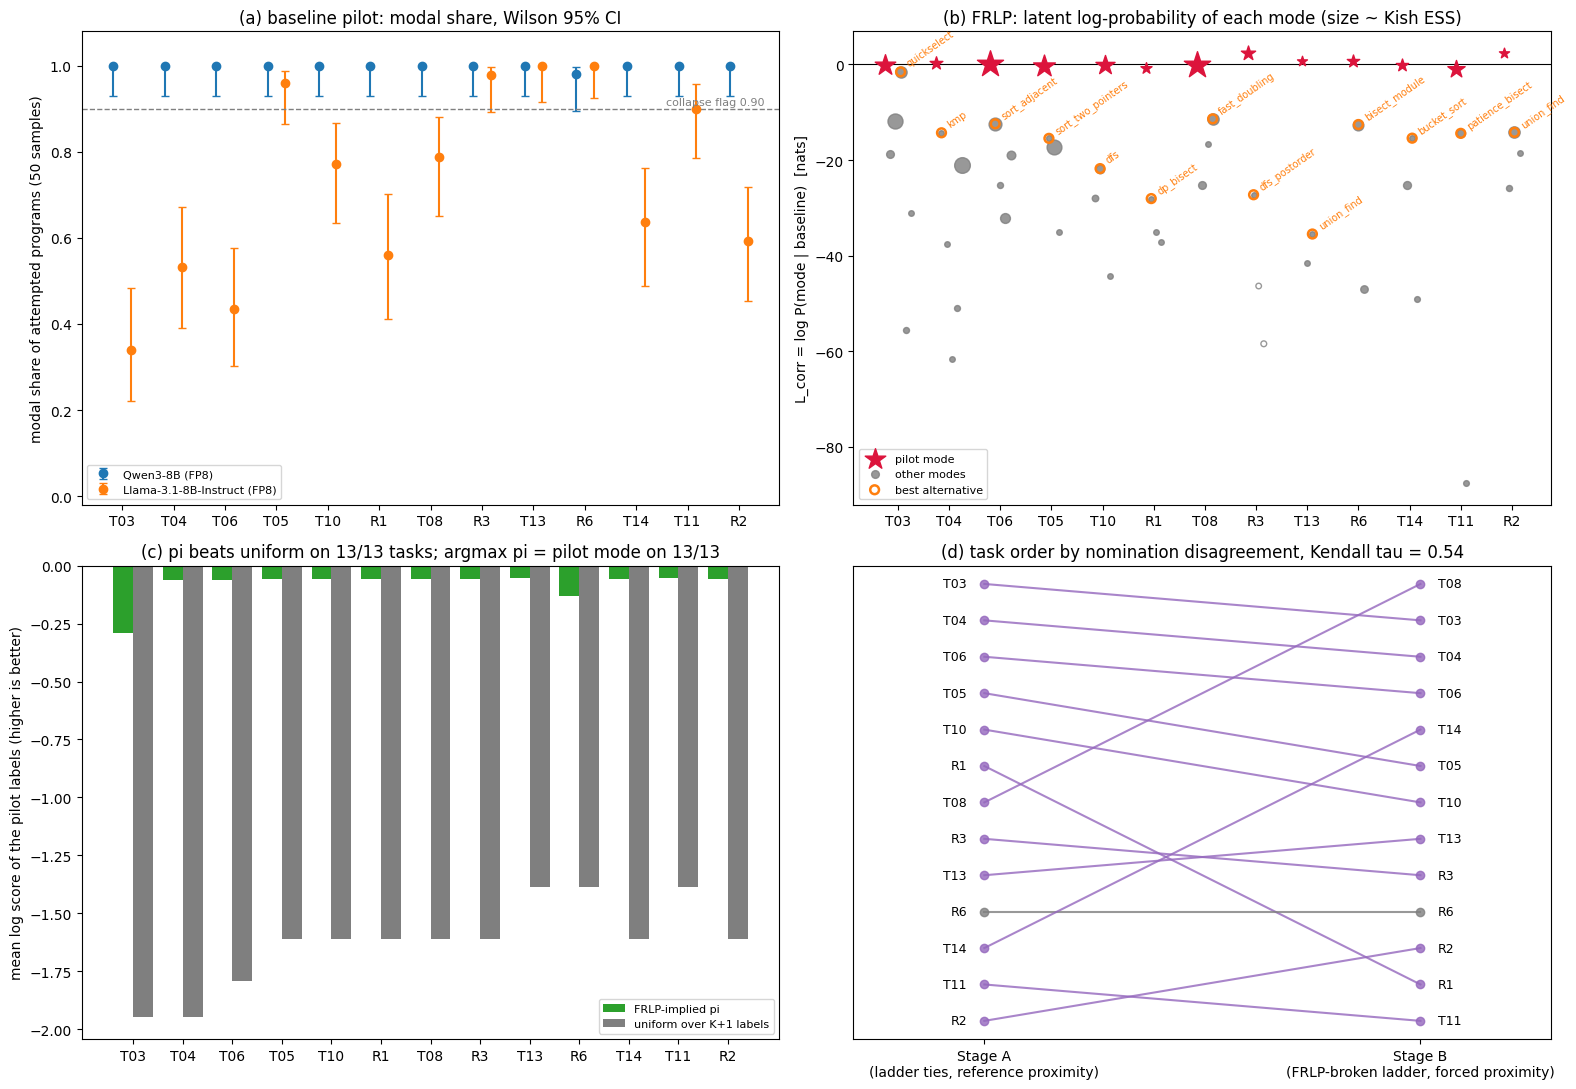

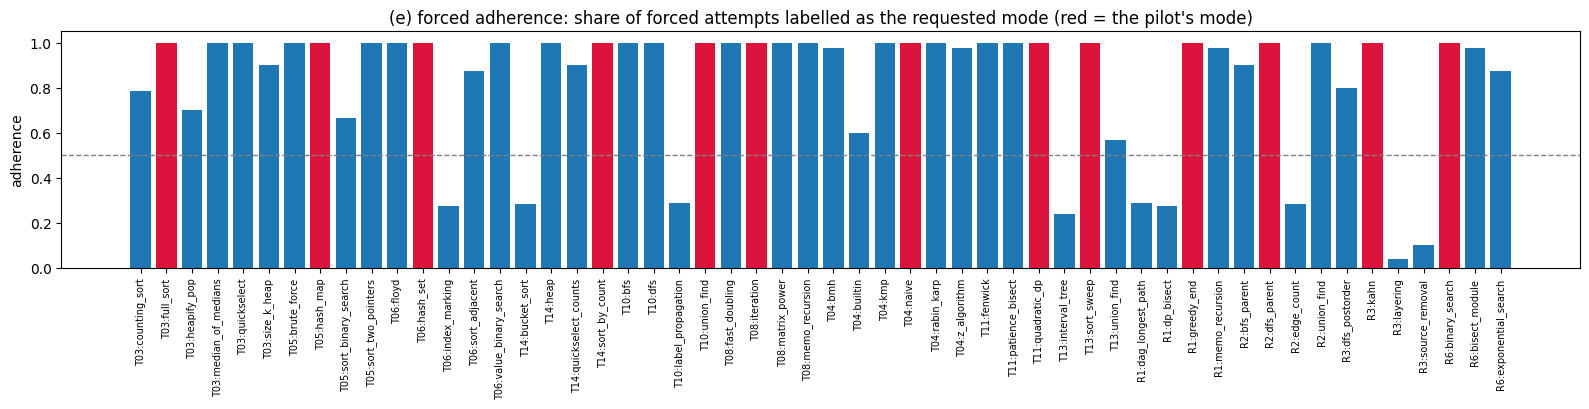

In [24]:
order_A = STAGE_A["order"]
x = np.arange(len(order_A))
fig, axs = plt.subplots(2, 2, figsize=(16, 11))

# (a) modal share with Wilson 95% CI, Qwen vs Llama
ax = axs[0, 0]
for off, stats_, lab, col in ((-0.17, PILOT_STATS, "Qwen3-8B (FP8)", "tab:blue"),
                              (0.17, LLAMA_STATS, "Llama-3.1-8B-Instruct (FP8)", "tab:orange")):
    ts = [t for t in order_A if t in stats_]
    xs = np.array([order_A.index(t) for t in ts]) + off
    y = np.array([stats_[t]["modal_share"] for t in ts])
    lo = np.array([stats_[t]["modal_share_ci95"][0] for t in ts])
    hi = np.array([stats_[t]["modal_share_ci95"][1] for t in ts])
    ax.errorbar(xs, y, yerr=[np.clip(y - lo, 0, None), np.clip(hi - y, 0, None)], fmt="o", capsize=3, color=col, label=lab)
ax.axhline(0.9, ls="--", c="gray", lw=1)
ax.text(len(order_A) - 0.5, 0.905, "collapse flag 0.90", ha="right", va="bottom", fontsize=8, color="gray")
ax.set_xticks(x, order_A)
ax.set_ylim(-0.02, 1.08)
ax.set_ylabel("modal share of attempted programs (50 samples)")
ax.set_title("(a) baseline pilot: modal share, Wilson 95% CI")
ax.legend(loc="lower left", fontsize=8)

# (b) FRLP L_corr of every mode
ax = axs[0, 1]
labeled = set()
for i, t in enumerate(order_A):
    modes = list(TASKS[t]["modes"])
    for k, j in enumerate(modes):
        c = MAIN[(t, j)]
        if c["L_corr"] is None:
            continue
        xi = i + (k - (len(modes) - 1) / 2) * 0.1
        excluded = "insufficient" in c["flags"]
        size = 12 + 4 * (c["ess"] or 0)
        kind = "pilot mode" if j == PILOT_STATS[t]["modal_label"] else "other modes"
        lab = None if kind in labeled else kind
        labeled.add(kind)
        if kind == "pilot mode":
            ax.scatter(xi, c["L_corr"], marker="*", s=size * 3, color="crimson", zorder=3, label=lab)
        else:
            ax.scatter(xi, c["L_corr"], s=size, facecolors="none" if excluded else "tab:gray",
                       edgecolors="tab:gray", alpha=0.8, label=lab)
    alt = next((r for r in SUMMARY if r["task"] == t), None)
    if alt and alt["best"] and alt["lc_best"] is not None:  # best alternative: orange, labelled
        k = list(TASKS[t]["modes"]).index(alt["best"])
        xb = i + (k - (len(modes) - 1) / 2) * 0.1
        ax.scatter(xb, alt["lc_best"], s=40, facecolors="none", edgecolors="tab:orange", linewidths=1.8, zorder=4,
                   label=None if "best alternative" in labeled else "best alternative")
        labeled.add("best alternative")
        ax.annotate(alt["best"], (xb, alt["lc_best"]), textcoords="offset points", xytext=(3, 4), ha="left",
                    fontsize=7, rotation=35, color="tab:orange")
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(x, order_A)
ax.set_ylabel("L_corr = log P(mode | baseline)  [nats]")
ax.set_title("(b) FRLP: latent log-probability of each mode (size ~ Kish ESS)")
ax.legend(loc="lower left", fontsize=8)

# (c) log score of the pilot labels: FRLP pi vs uniform
ax = axs[1, 0]
ls_pi = [VAL[t]["log_score_pi"] if VAL[t]["log_score_pi"] is not None else np.nan for t in order_A]
ls_u = [VAL[t]["log_score_uniform"] for t in order_A]
ax.bar(x - 0.2, ls_pi, 0.4, label="FRLP-implied pi", color="tab:green")
ax.bar(x + 0.2, ls_u, 0.4, label="uniform over K+1 labels", color="tab:gray")
ax.set_xticks(x, order_A)
ax.set_ylabel("mean log score of the pilot labels (higher is better)")
ax.set_title(f"(c) pi beats uniform on {sum(np.nan_to_num(np.array(ls_pi), nan=-1e9) > np.array(ls_u))}/{len(order_A)} tasks; "
             f"argmax pi = pilot mode on {sum(VAL[t]['argmax_matches_pilot_mode'] for t in order_A)}/{len(order_A)}")
ax.legend(fontsize=8)

# (d) Stage A vs Stage B ranks
ax = axs[1, 1]
rank_b = {t: i for i, t in enumerate(STAGE_B["order"])}
for i, t in enumerate(order_A):
    ax.plot([0, 1], [i, rank_b[t]], "-o", color="tab:purple" if i != rank_b[t] else "tab:gray", alpha=0.8)
    ax.text(-0.04, i, t, ha="right", va="center", fontsize=9)
    ax.text(1.04, rank_b[t], t, ha="left", va="center", fontsize=9)
ax.set_xlim(-0.3, 1.3)
ax.set_ylim(len(order_A) - 0.5, -0.5)
ax.set_xticks([0, 1], ["Stage A\n(ladder ties, reference proximity)", "Stage B\n(FRLP-broken ladder, forced proximity)"])
ax.set_yticks([])
ax.set_title(f"(d) task order by nomination disagreement, Kendall tau = {TAU:.2f}")
plt.tight_layout()
plt.show()

# (e) forced adherence per mode
items = [(k, v["adherence"]) for k, v in ADH.items()]
items.sort(key=lambda kv: (FULL_TASK_ORDER.index(kv[0].split(":")[0]), kv[0]))
fig, ax = plt.subplots(figsize=(16, 4.2))
cols = ["crimson" if k.split(":")[1] == PILOT_STATS[k.split(":")[0]]["modal_label"] else "tab:blue" for k, _ in items]
ax.bar(range(len(items)), [a for _, a in items], color=cols)
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_xticks(range(len(items)), [k for k, _ in items], rotation=90, fontsize=7)
ax.set_ylabel("adherence")
ax.set_title("(e) forced adherence: share of forced attempts labelled as the requested mode (red = the pilot's mode)")
plt.tight_layout()
plt.show()

## Takeaways

- **Collapse.** Under plain sampling (T = 1.0, top_p = 1), Qwen3-8B writes the same algorithm in all 50 of 50 samples on 12 of 13 tasks; the 13th is R6, at 49/50. Qwen raises the collapse flag on 13/13 tasks. Llama-3.1-8B-Instruct, given the same prompts and decoding, raises it on only 5/13 and spreads over several modes elsewhere (T03: heapify_pop 0.34), though it passes far fewer tests.
- **Latent alternatives.** The forced-program importance sampler gives each alternative a latent mass that is small but measurable. For example, T03 *quickselect* has L_corr ≈ −1.5, about 0.21 of the latent mass, while the pilot shows it 0 of 50 times. The argmax of the FRLP-implied distribution recovers the pilot mode on 13/13 tasks, and it beats the uniform log score on 13/13. The estimator is noisy, though: 34/54 cells have a Kish ESS below 5, and S stays in [0.3, 3] on only 11/13 tasks (R2 and R3 overshoot).
- **Nominations disagree.** What the model *says* is the standard alternative (association) and which programs are closest (proximity) often name different modes. This disagreement sets the task order for the later ban experiments.
- **Reproducibility.** Every number above was re-derived from the recorded rows with the original code. Only the GPU sampling and scoring, the sandboxed tracer and the judge calls come from the recording. The hash chain in `commitments.log` ties the frozen bench to those recorded outputs.